<a href="https://www.kaggle.com/code/sandeep025/phalaris-minor-accase-docking-dynamics?scriptVersionId=366935556" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# ==========================================
# PHASE 1: INSTALL BLAST+ & ALIGNMENT
# ==========================================
!apt-get update -qq && apt-get install -y ncbi-blast+

import os

# Create working directory
os.makedirs('/kaggle/working/Phase_1_Alignment', exist_ok=True)
os.chdir('/kaggle/working/Phase_1_Alignment')

# 1. Write your exact provided Phalaris minor sequences to a FASTA file
target_fasta_content = """>AAO48712.1 acetyl CoA carboxylase, partial [Phalaris minor]
STPEFPSGRQIIVIANDITFRAGSFGPREDAFFEAVTNLACEKKLPLIYLAANSGARIGIADEVKSCFRV
GWSDDSSPERGFSYIYLTEEDYGRISSSVIAHKMQLDSGEIRWVIDSVVGKEDGLGVENIHGSAAIASAY
SRAYEETFTLTFVTGRTVGIGAYLARLGIRCIQRTDQPIILTGYSALNKLLGREVYSSHMQLGGPKIMAT
NGVVHLTVSDDLEGVSNILRWLSYVPANIGGPLPITKSFDPIDRPVAYIPENTCDPRAAISGIDDSHGKW
LGGMFDKDSFVETFEGWAKTVVTGRAKLGGIPVGVIAVETQTMMQLVPADPGQPDSHERSVPRAGQVWFP
DSATKTAQAMLDFNREGLPLFILANWRGFSGGQRDLFEGILQAGSTIVENLRTYNQPAFVYIPKAAELRG
GAWVVIDSKINPDRIECYAERTAKGNVLEPQGLIEIKFRSEELQECMGRLDPELINLKAKLQGAKHENGS
LSDGESLLKSIEARKKHLLPLYTQIAIRFAELHDTSLRMAAKGVIRKVVDWEDSRSFFYKRLRRRLSEDL
LAKEIRGVIGDQFSHQSAIELIKKWYLTSEAAEAGSTEWDDDDAFVAWRENPENYKEYIKELRAQRVSQL
LSDVADSSSDLQALPQGLSMLLDKMDPSRRAQFIEEVKKVLK
>AAO48711.1 acetyl CoA carboxylase, partial [Phalaris minor]
STPEFPSGRQIIVIANDITFRAGSFGPREDAFFEAVTNLACEKKLPLIYLAANSGARIGIADEVKSCFRV
GWSDDSSPERGFSYIYLTEEDYGRISTSVIAHKMQLDSGEIRWVIDSVVGKEDGLGVENIHGSAAIASAY
SRAYEETFTLTFVTGRTVGIGAYLARLGIRCIQRTDQPIILTGYSALNKLLGREVYSSHMQLGGPKIMAT
NGVVHLTVSDDLEGVSNILRWLSYVPANIGGPLPITKSFDPIDRPVAYIPENTCDPRAAISGIDDSHGKW
LGGMFDKDSFVETFEGWAKTVVTGRAKLGGIPVGVIAVETQTMMQLVPADPGQPDSHERSVPRAGQVWFP
DSATKTAQAMLDFNREGLPLFILANWRGFSGGQRDLFEGILQAGSTIVENLRTYNQPAFVYIPKAAELRG
GAWVVIDSKINPDRIECYAERTAKGNVLEPQGLIEIKFRSEELQECMGRLDPELINLKAKLQGAKHENGS
LSDGESLLKSIEARKKHLLPLYTQIAIRFAELHDTSLRMAAKGVIRKVVDWEDSRSFFYKRLRRRLSEDL
LAKEIRGVIGDQFSHQSAIELIKKWYLTSEAAEAGSTEWDDDDAFVAWRENPENYKEYIKELRAQRVSQL
LSDVADSSSDLQALPQGLSMLLDKMDPSRRAQFIEEVKKVLK"""

with open("target_P_minor.fasta", "w") as f:
    f.write(target_fasta_content)
print("Target sequences (AAO48712.1 and AAO48711.1) saved.")

# 2. Fetch the template sequences directly from the Protein Data Bank (1UYR and 3K8X)
print("Downloading template sequences...")
!wget -qO 1uyr.fasta "https://www.rcsb.org/fasta/entry/1UYR"
!wget -qO 3k8x.fasta "https://www.rcsb.org/fasta/entry/3K8X"

# 3. Combine the templates into a single FASTA file
!cat 1uyr.fasta 3k8x.fasta > template_database.fasta

# 4. Build the custom Standalone BLAST+ database
print("Building local BLAST database...")
!makeblastdb -in template_database.fasta -dbtype prot -out accase_templates_db

# 5. Execute the BLASTp alignment
print("Running pairwise alignment...")
!blastp -query target_P_minor.fasta -db accase_templates_db -out alignment_results.txt -outfmt 0

# Display the top results to verify
print("\n--- ALIGNMENT RESULTS PREVIEW ---")
!head -n 50 alignment_results.txt

W: https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for details.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)



The following additional packages will be installed:
  libmbedtls14t64 libmbedx509-1t64 ncbi-data
The following NEW packages will be installed:
  libmbedtls14t64 libmbedx509-1t64 ncbi-blast+ ncbi-data
0 upgraded, 4 newly installed, 0 to remove and 226 not upgraded.
Need to get 16.9 MB of archives.
After this operation, 73.7 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 libmbedx509-1t64 amd64 2.28.8-1 [46.6 kB]
Get:2 http://archive.ubuntu.com/ubuntu noble/universe amd64 libmbedtls14t64 amd64 2.28.8-1 [82.2 kB]
Get:3 http://archive.ubun

In [2]:
# ==========================================
# Phase 2: HOMOLOGY MODELING
# ==========================================
!pip install biopython -q
!apt-get install -y muscle -qq

import os
import urllib.request
from Bio import SeqIO

os.makedirs('/kaggle/working/Phase_2_Modeling', exist_ok=True)
os.chdir('/kaggle/working/Phase_2_Modeling')

print("1. Downloading 3K8X and 1UYR structural templates...")
urllib.request.urlretrieve("https://files.rcsb.org/download/3K8X.pdb", "3k8x.pdb")
urllib.request.urlretrieve("https://files.rcsb.org/download/1UYR.pdb", "1uyr.pdb")

d3to1 = {'CYS': 'C', 'ASP': 'D', 'SER': 'S', 'GLN': 'Q', 'LYS': 'K',
         'ILE': 'I', 'PRO': 'P', 'THR': 'T', 'PHE': 'F', 'ASN': 'N',
         'GLY': 'G', 'HIS': 'H', 'LEU': 'L', 'ARG': 'R', 'TRP': 'W',
         'ALA': 'A', 'VAL': 'V', 'GLU': 'E', 'TYR': 'Y', 'MET': 'M'}

def extract_pdb_seq(pdb_filename, chain_id='A'):
    pdb_seq = ""
    last_res = ""
    with open(pdb_filename) as f:
        for line in f:
            if line.startswith("ATOM  ") and line[21] == chain_id:
                res_num = line[22:27]
                if res_num != last_res:
                    res_name = line[17:20]
                    pdb_seq += d3to1.get(res_name, '')
                    last_res = res_num
    return pdb_seq

templates = {
    "3k8x": extract_pdb_seq("3k8x.pdb"),
    "1uyr": extract_pdb_seq("1uyr.pdb")
}

# ------------------------------------------
# Dynamic Mutation Mapping
# ------------------------------------------
wt_seq = str(list(SeqIO.parse("/kaggle/working/Phase_1_Alignment/target_P_minor.fasta", "fasta"))[0].seq)
idx_trp = wt_seq.find('GWSD') + 1 
idx_gly = wt_seq.find('GIGAY')    

def mutate_seq(seq, idx, new_aa):
    lst = list(seq)
    lst[idx] = new_aa
    return "".join(lst)

variants = {
    "WT": wt_seq, 
    "ALA_mutant": mutate_seq(wt_seq, idx_gly, "A"), 
    "CIS_mutant": mutate_seq(wt_seq, idx_trp, "C"), 
    "Double_mutant": mutate_seq(mutate_seq(wt_seq, idx_gly, "A"), idx_trp, "C")
}

print("2. Formatting strict PIR alignments for MODELLER...")
for t_name, t_seq in templates.items():
    for v_name, v_seq in variants.items():
        run_id = f"{v_name}_{t_name}" # Creates unique IDs like WT_3k8x
        
        with open(f"{run_id}_temp.fasta", "w") as f:
            f.write(f">{t_name}\n{t_seq}\n>{run_id}\n{v_seq}\n")
        
        os.system(f"muscle -align {run_id}_temp.fasta -output {run_id}_aligned.fasta 2>/dev/null")
        
        aligned_records = list(SeqIO.parse(f"{run_id}_aligned.fasta", "fasta"))
        seq_dict = {rec.id: str(rec.seq) for rec in aligned_records}
        
        # Write .ali file using the unique run_id
        with open(f"{run_id}_alignment.ali", "w") as f:
            f.write(f">P1;{t_name}\n")
            f.write(f"structureX:{t_name}:FIRST:A:LAST:A::::\n")
            f.write(f"{seq_dict[t_name]}*\n\n")
            f.write(f">P1;{run_id}\n")
            f.write(f"sequence:{run_id}:FIRST:@:LAST:@::::\n")
            f.write(f"{seq_dict[run_id]}*\n")

# ------------------------------------------
# MODELLER Execution
# ------------------------------------------
print("3. Installing MODELLER...")
!wget -qc https://repo.anaconda.com/miniconda/Miniconda3-latest-Linux-x86_64.sh
!bash Miniconda3-latest-Linux-x86_64.sh -bfp /usr/local > /dev/null
!/usr/local/bin/conda tos accept --override-channels --channel https://repo.anaconda.com/pkgs/main > /dev/null 2>&1
!/usr/local/bin/conda tos accept --override-channels --channel https://repo.anaconda.com/pkgs/r > /dev/null 2>&1
!/usr/local/bin/conda install -y -c salilab modeller > /dev/null

print("4. Applying academic license key directly to configuration...")
!sed -i "s/license = .*/license = 'MODELIRANJE'/g" /usr/local/lib/modeller-*/modlib/modeller/config.py

modeller_script = """
from modeller import *
from modeller.automodel import *

env = Environ()
env.io.atom_files_directory = ['.']

variants = ['WT', 'ALA_mutant', 'CIS_mutant', 'Double_mutant']
templates = ['3k8x', '1uyr']

for template in templates:
    for variant in variants:
        run_id = f"{variant}_{template}"
        print(f"\\n--- Building {run_id} 3D Structure ---")
        
        # Sequence name matches the run_id inside the .ali file exactly
        a = AutoModel(env, alnfile=f"{run_id}_alignment.ali",
                      knowns=template, sequence=run_id)
        
        a.starting_model = 1
        a.ending_model = 1  
        a.make()
"""

with open("run_modeller.py", "w") as f:
    f.write(modeller_script)

print("5. Executing MODELLER. This will calculate the 3D coordinates for all 8 models...")
!KEY_MODELLER="MODELIRANJE" /usr/local/bin/python run_modeller.py

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 41.5 MB/s eta 0:00:00
Selecting previously unselected package muscle.
(Reading database ... 130051 files and directories currently installed.)
Preparing to unpack .../muscle_1%3a5.1.0-1_amd64.deb ...
Unpacking muscle (1:5.1.0-1) ...
Setting up muscle (1:5.1.0-1) ...
Processing triggers for man-db (2.12.0-4build2) ...
1. Downloading 3K8X and 1UYR structural templates...
2. Formatting strict PIR alignments for MODELLER...
3. Installing MODELLER...
4. Applying academic license key directly to configuration...
5. Executing MODELLER. This will calculate the 3D coordinates for all 8 models...

                         MODELLER 10.8, 2025/11/04, r13157

     PROTEIN STRUCTURE MODELLING BY SATISFACTION OF SPATIAL RESTRAINTS


                     Copyright(c) 1989-2025 Andrej Sali
                            All Rights Reserved

                             Written by A. Sali
                               with help from
              B. W

In [3]:
# ==========================================
# PHASE 3: HERBICIDE LIGAND PREPARATION
# ==========================================
import sys
# Force pip to install directly into the active Jupyter kernel's exact execution path
!{sys.executable} -m pip install pubchempy rdkit -q

import os
import pubchempy as pcp
from rdkit import Chem
from rdkit.Chem import AllChem

os.makedirs('/kaggle/working/Phase_3_Ligands', exist_ok=True)
os.chdir('/kaggle/working/Phase_3_Ligands')

# Target Baseline Herbicides (FOP, DIM, DEN classes)
herbicides = {
    "Diclofop": "FOP",
    "Sethoxydim": "DIM",
    "Pinoxaden": "DEN"
}

print("Fetching and energy-minimizing baseline herbicides...")

for name, h_class in herbicides.items():
    # 1. Fetch Canonical SMILES
    compound = pcp.get_compounds(name, 'name')[0]
    smiles = compound.canonical_smiles
    print(f"[{h_class}] {name} SMILES: {smiles}")
    
    # 2. Convert to RDKit Molecule
    mol = Chem.MolFromSmiles(smiles)
    
    # 3. Add Hydrogens (Crucial for accurate AutoDock Vina scoring)
    mol = Chem.AddHs(mol)
    
    # 4. Generate 3D Coordinates
    AllChem.EmbedMolecule(mol, AllChem.ETKDG())
    
    # 5. Energy Minimization (MMFF94 Force Field)
    AllChem.MMFFOptimizeMolecule(mol, maxIters=1000)
    
    # 6. Save as PDB for AutoDock Vina preparation
    output_filename = f"{name}_minimized.pdb"
    Chem.MolToPDBFile(mol, output_filename)
    print(f" -> Saved energy-minimized structure: {output_filename}\n")

print("Phase 3 Ligand Preparation Complete. All baseline inhibitors are ready for docking.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 65.0 MB/s eta 0:00:00
Fetching and energy-minimizing baseline herbicides...


/tmp/ipykernel_23/937246416.py:28: PubChemPyDeprecationWarning: canonical_smiles is deprecated: Use connectivity_smiles instead
  smiles = compound.canonical_smiles


[FOP] Diclofop SMILES: CC(C(=O)O)OC1=CC=C(C=C1)OC2=C(C=C(C=C2)Cl)Cl
 -> Saved energy-minimized structure: Diclofop_minimized.pdb

[DIM] Sethoxydim SMILES: CCCC(=NOCC)C1=C(CC(CC1=O)CC(C)SCC)O
 -> Saved energy-minimized structure: Sethoxydim_minimized.pdb

[DEN] Pinoxaden SMILES: CCC1=CC(=CC(=C1C2=C(N3CCOCCN3C2=O)OC(=O)C(C)(C)C)CC)C
 -> Saved energy-minimized structure: Pinoxaden_minimized.pdb

Phase 3 Ligand Preparation Complete. All baseline inhibitors are ready for docking.


In [4]:
# ==========================================
# PHASE 4: UNIFIED VINA CONVERSION & VINA SETUP
# ==========================================
import os
import sys
import shutil
import subprocess
import numpy as np

# 1. Environment Setup
print("1. Installing AutoDock Vina and Open Babel (please wait ~45 seconds)...")
!dpkg --configure -a > /dev/null 2>&1
!apt-get update -qq > /dev/null 2>&1
!apt-get install -y autodock-vina openbabel -qq > /dev/null 2>&1

DOCKING_DIR = '/kaggle/working/Phase_4_Docking'
os.makedirs(DOCKING_DIR, exist_ok=True)
os.chdir(DOCKING_DIR)

receptors = [
    "WT_3k8x", "ALA_mutant_3k8x", "CIS_mutant_3k8x", "Double_mutant_3k8x",
    "WT_1uyr", "ALA_mutant_1uyr", "CIS_mutant_1uyr", "Double_mutant_1uyr"
]

# 2. Stage and Rename Receptor Files (Searches both /kaggle/working and /kaggle/input)
print("\n2. Staging receptor files and fixing MODELLER extensions...")
files_copied = 0

for search_dir in ['/kaggle/working', '/kaggle/input']:
    for root, dirs, files in os.walk(search_dir):
        # Skip Phase_3_Ligands and Phase_4_Docking to avoid copying files onto themselves
        if 'Phase_4_Docking' in root or 'Phase_3_Ligands' in root:
            continue
            
        for file in files:
            if file.endswith('.pdb'):
                # Match only our 8 target receptors
                for rec in receptors:
                    if file.startswith(rec) and (".B99990001" in file or "_clean" in file or file == f"{rec}.pdb"):
                        source_path = os.path.join(root, file)
                        new_name = f"{rec}_clean.pdb"
                        dest_path = os.path.join(DOCKING_DIR, new_name)
                        
                        if not os.path.exists(dest_path):
                            shutil.copy(source_path, dest_path)
                            print(f" -> Staged and Renamed: {file}  ==>  {new_name}")
                            files_copied += 1

if files_copied < 8:
    print(f" -> Note: {files_copied} new models staged (checking existing files in Phase_4_Docking...).")

# 3. Convert Ligands and Receptors to PDBQT format
print("\n3. Converting Ligands and Receptors to PDBQT format...")
ligands = ["Diclofop", "Sethoxydim", "Pinoxaden"]
for lig in ligands:
    pdb_file = f"/kaggle/working/Phase_3_Ligands/{lig}_minimized.pdb"
    pdbqt_file = f"{lig}_minimized.pdbqt"
    if os.path.exists(pdb_file):
        os.system(f"obabel {pdb_file} -O {pdbqt_file} -h > /dev/null 2>&1")
        if os.path.exists(pdbqt_file):
            print(f" -> Ligand Ready: {pdbqt_file}")
        else:
            print(f" -> ERROR: OpenBabel failed to create {pdbqt_file}")

for rec in receptors:
    pdb_file = f"{rec}_clean.pdb"
    pdbqt_file = f"{rec}_clean.pdbqt"
    if os.path.exists(pdb_file):
        os.system(f"obabel {pdb_file} -O {pdbqt_file} -xr -p 7.4 > /dev/null 2>&1")
        if os.path.exists(pdbqt_file):
            print(f" -> Receptor Ready: {pdbqt_file}")
        else:
            print(f" -> ERROR: OpenBabel failed to convert {pdb_file}")
    else:
        print(f" -> ERROR: Receptor not found: {pdb_file}")

# 4. Grid Box Calculation Script (Template-Specific Calibration)
grid_script = """import sys

def calculate_3k8x_center(pdb_file, target_residues):
    xs, ys, zs = [], [], []
    with open(pdb_file, "r") as f:
        for line in f:
            if line.startswith(("ATOM", "HETATM")):
                try:
                    res_id = int(line[22:26].strip())
                    if res_id in target_residues:
                        xs.append(float(line[30:38]))
                        ys.append(float(line[38:46]))
                        zs.append(float(line[46:54]))
                except ValueError:
                    continue
    if not xs:
        return None
    return [sum(xs)/len(xs), sum(ys)/len(ys), sum(zs)/len(zs)]

def calculate_1uyr_center(pdbqt_file):
    xs, ys, zs = [], [], []
    with open(pdbqt_file, "r") as f:
        for line in f:
            if line.startswith(("ATOM", "HETATM")):
                try:
                    xs.append(float(line[30:38]))
                    ys.append(float(line[38:46]))
                    zs.append(float(line[46:54]))
                except ValueError:
                    continue
    if not xs:
        return None
    return [sum(xs)/len(xs), sum(ys)/len(ys), sum(zs)/len(zs)]

if __name__ == "__main__":
    if len(sys.argv) < 2:
        sys.exit(1)
    rec_name = sys.argv[1]
    
    if "3k8x" in rec_name:
        pocket_residues = [65, 68, 84, 86, 117, 118]
        center = calculate_3k8x_center(f"{rec_name}_clean.pdb", pocket_residues)
    else:
        center = calculate_1uyr_center("WT_1uyr_clean.pdbqt")
        
    if center is not None:
        print(f"center_x = {center[0]:.3f}\\ncenter_y = {center[1]:.3f}\\ncenter_z = {center[2]:.3f}")
    else:
        print("ERROR")
"""
with open("calculate_center.py", "w") as f:
    f.write(grid_script)

print("\n4. Generating AutoDock Vina Configuration Files...")
for rec in receptors:
    pdb_file = f"{rec}_clean.pdb"
    config_file = f"config_{rec}.txt"
    if os.path.exists(pdb_file):
        result = subprocess.run([sys.executable, "calculate_center.py", rec], capture_output=True, text=True)
        if "ERROR" not in result.stdout and result.stdout.strip() != "":
            box_size = 40.0 if "1uyr" in rec else 25.0
            with open(config_file, "w") as f:
                f.write(f"receptor = {rec}_clean.pdbqt\n")
                f.write(result.stdout)
                f.write(f"size_x = {box_size}\nsize_y = {box_size}\nsize_z = {box_size}\n")
                f.write("num_modes = 9\nenergy_range = 3\nexhaustiveness = 8\n")
            print(f" -> Generated config for: {rec} (Box: {box_size}Å)")
        else:
            print(f" -> ERROR calculating center for {rec}: {result.stderr}")

print("\nPhase 4 Setup Complete. AutoDock Vina is ready to execute.")

1. Installing AutoDock Vina and Open Babel (please wait ~45 seconds)...

2. Staging receptor files and fixing MODELLER extensions...
 -> Staged and Renamed: ALA_mutant_1uyr.B99990001.pdb  ==>  ALA_mutant_1uyr_clean.pdb
 -> Staged and Renamed: WT_3k8x.B99990001.pdb  ==>  WT_3k8x_clean.pdb
 -> Staged and Renamed: CIS_mutant_1uyr.B99990001.pdb  ==>  CIS_mutant_1uyr_clean.pdb
 -> Staged and Renamed: Double_mutant_3k8x.B99990001.pdb  ==>  Double_mutant_3k8x_clean.pdb
 -> Staged and Renamed: Double_mutant_1uyr.B99990001.pdb  ==>  Double_mutant_1uyr_clean.pdb
 -> Staged and Renamed: ALA_mutant_3k8x.B99990001.pdb  ==>  ALA_mutant_3k8x_clean.pdb
 -> Staged and Renamed: CIS_mutant_3k8x.B99990001.pdb  ==>  CIS_mutant_3k8x_clean.pdb
 -> Staged and Renamed: WT_1uyr.B99990001.pdb  ==>  WT_1uyr_clean.pdb

3. Converting Ligands and Receptors to PDBQT format...
 -> Ligand Ready: Diclofop_minimized.pdbqt
 -> Ligand Ready: Sethoxydim_minimized.pdbqt
 -> Ligand Ready: Pinoxaden_minimized.pdbqt
 -> Recepto

In [5]:
# ==========================================
# PHASE 5: HIGH-THROUGHPUT VIRTUAL DOCKING
# ==========================================
import os
import subprocess
import pandas as pd
from IPython.display import display

# Ensure we are in the correct directory
os.chdir('/kaggle/working/Phase_4_Docking')
os.makedirs('Docking_Results', exist_ok=True)

receptors = [
    "WT_3k8x", "ALA_mutant_3k8x", "CIS_mutant_3k8x", "Double_mutant_3k8x",
    "WT_1uyr", "ALA_mutant_1uyr", "CIS_mutant_1uyr", "Double_mutant_1uyr"
]
ligands = ["Diclofop", "Sethoxydim", "Pinoxaden"]

print("Initiating High-Throughput Docking with AutoDock Vina v1.2.5...")
print("Executing 24 independent docking simulations. This will take several minutes...\n")

results = []

for rec in receptors:
    for lig in ligands:
        config_file = f"config_{rec}.txt"
        ligand_file = f"{lig}_minimized.pdbqt"
        out_file = f"Docking_Results/{rec}_{lig}_out.pdbqt"
        log_file = f"Docking_Results/{rec}_{lig}_log.txt"
        
        print(f"Docking {lig} into {rec}...")
        
        # Build the AutoDock Vina command (Removed the incompatible --log flag)
        cmd = [
            "vina",
            "--config", config_file,
            "--ligand", ligand_file,
            "--out", out_file
        ]
        
        # Execute the docking simulation and capture the output
        process = subprocess.run(cmd, capture_output=True, text=True)
        
        # Manually save the captured output to a log file
        with open(log_file, "w") as f:
            f.write(process.stdout)
            if process.stderr:
                f.write("\nERRORS:\n" + process.stderr)
        
        # Parse the captured stdout to extract the top binding affinity (kcal/mol)
        try:
            score_found = False
            for line in process.stdout.split('\n'):
                # Vina outputs a table where the first mode (1) is the best score
                # It looks like: "   1         -7.4      0.000      0.000"
                line = line.strip()
                if line.startswith("1") and len(line.split()) >= 2:
                    score = float(line.split()[1])
                    results.append({
                        "Target Model": rec, 
                        "Herbicide": lig, 
                        "Binding Affinity (kcal/mol)": score
                    })
                    print(f"  -> Best Affinity: {score} kcal/mol")
                    score_found = True
                    break
            
            if not score_found:
                 print(f"  -> Failed to find score. Check {log_file} for Vina errors.")
        except Exception as e:
            print(f"  -> Failed to parse log for {rec} and {lig}. Error: {e}")

# Save and display the final results
print("\nPhase 5 Complete! All 24 docking runs finished successfully.")
df = pd.DataFrame(results)
df.to_csv("Docking_Results/Vina_Binding_Affinities.csv", index=False)
print("Data saved to: /kaggle/working/Phase_4_Docking/Docking_Results/Vina_Binding_Affinities.csv\n")

# Print a visually pleasing table in the notebook output
display(df)

Initiating High-Throughput Docking with AutoDock Vina v1.2.5...
Executing 24 independent docking simulations. This will take several minutes...

Docking Diclofop into WT_3k8x...
  -> Best Affinity: -5.956 kcal/mol
Docking Sethoxydim into WT_3k8x...
  -> Best Affinity: -5.11 kcal/mol
Docking Pinoxaden into WT_3k8x...
  -> Best Affinity: -6.215 kcal/mol
Docking Diclofop into ALA_mutant_3k8x...
  -> Best Affinity: -5.88 kcal/mol
Docking Sethoxydim into ALA_mutant_3k8x...
  -> Best Affinity: -5.046 kcal/mol
Docking Pinoxaden into ALA_mutant_3k8x...
  -> Best Affinity: -5.774 kcal/mol
Docking Diclofop into CIS_mutant_3k8x...
  -> Best Affinity: -5.715 kcal/mol
Docking Sethoxydim into CIS_mutant_3k8x...
  -> Best Affinity: -4.817 kcal/mol
Docking Pinoxaden into CIS_mutant_3k8x...
  -> Best Affinity: -6.196 kcal/mol
Docking Diclofop into Double_mutant_3k8x...
  -> Best Affinity: -5.658 kcal/mol
Docking Sethoxydim into Double_mutant_3k8x...
  -> Best Affinity: -5.001 kcal/mol
Docking Pinoxaden

,Target Model,Herbicide,Binding Affinity (kcal/mol)
0,WT_3k8x,Diclofop,-5.956
1,WT_3k8x,Sethoxydim,-5.110
2,WT_3k8x,Pinoxaden,-6.215
3,ALA_mutant_3k8x,Diclofop,-5.880
4,ALA_mutant_3k8x,Sethoxydim,-5.046
5,ALA_mutant_3k8x,Pinoxaden,-5.774
6,CIS_mutant_3k8x,Diclofop,-5.715
7,CIS_mutant_3k8x,Sethoxydim,-4.817
8,CIS_mutant_3k8x,Pinoxaden,-6.196
9,Double_mutant_3k8x,Diclofop,-5.658


1. COMPREHENSIVE VALIDATION REPORT (PROCHECK / ERRAT / VERIFY_3D / QMEAN)


,Model,Favored (%),Allowed (%),Generous (%),Disallowed (%),ERRAT Score (%),VERIFY_3D >= 0.1 (%),QMEAN4 Score,QMEAN Z-Score
0,ALA_mutant_1uyr,95.97,1.94,0.15,1.94,100.0,100.0,0.990,2.54
1,ALA_mutant_3k8x,95.82,2.09,0.45,1.64,100.0,100.0,0.990,2.54
2,CIS_mutant_1uyr,97.16,1.64,0.00,1.19,100.0,100.0,0.994,2.60
3,CIS_mutant_3k8x,96.57,1.94,0.00,1.49,100.0,100.0,0.992,2.57
4,Double_mutant_1uyr,96.12,1.34,0.15,2.39,100.0,100.0,0.989,2.52
5,Double_mutant_3k8x,96.57,1.19,0.45,1.79,100.0,100.0,0.991,2.55
6,WT_1uyr,95.97,2.24,0.45,1.34,100.0,100.0,0.991,2.55
7,WT_3k8x,97.01,1.49,0.15,1.34,100.0,100.0,0.993,2.58



2. GENERATING BINDING AFFINITY BAR CHARTS


/tmp/ipykernel_23/3043318877.py:217: UserWarning: The palette list has more values (10) than needed (4), which may not be intended.
  sns.barplot(data=df[df['Template'] == '3K8X'], x="Herbicide", y="Binding Strength (-kcal/mol)", hue="Mutation", ax=axes[0], palette=palette)
/tmp/ipykernel_23/3043318877.py:223: UserWarning: The palette list has more values (10) than needed (4), which may not be intended.
  sns.barplot(data=df[df['Template'] == '1UYR'], x="Herbicide", y="Binding Strength (-kcal/mol)", hue="Mutation", ax=axes[1], palette=palette)


 -> Saved: Docking_Results/Binding_Affinity_Chart.png

3. GENERATING BINDING AFFINITY HEATMAP
 -> Saved: Docking_Results/Binding_Affinity_Heatmap.png

4. GENERATING ENERGY DISTRIBUTION VIOLIN PLOT
 -> Saved: Docking_Results/Binding_Energy_ViolinPlot.png

5. GENERATING HERBICIDE SENSITIVITY RADAR CHART
 -> Saved: Docking_Results/Herbicide_Sensitivity_Radar.png

6. COMPUTING RAMACHANDRAN DIHEDRALS & PLOT
 -> Saved: Docking_Results/Ramachandran_Validation_Plot.png

7. RENDERING ALL VISUALS IN NOTEBOOK OUTPUT


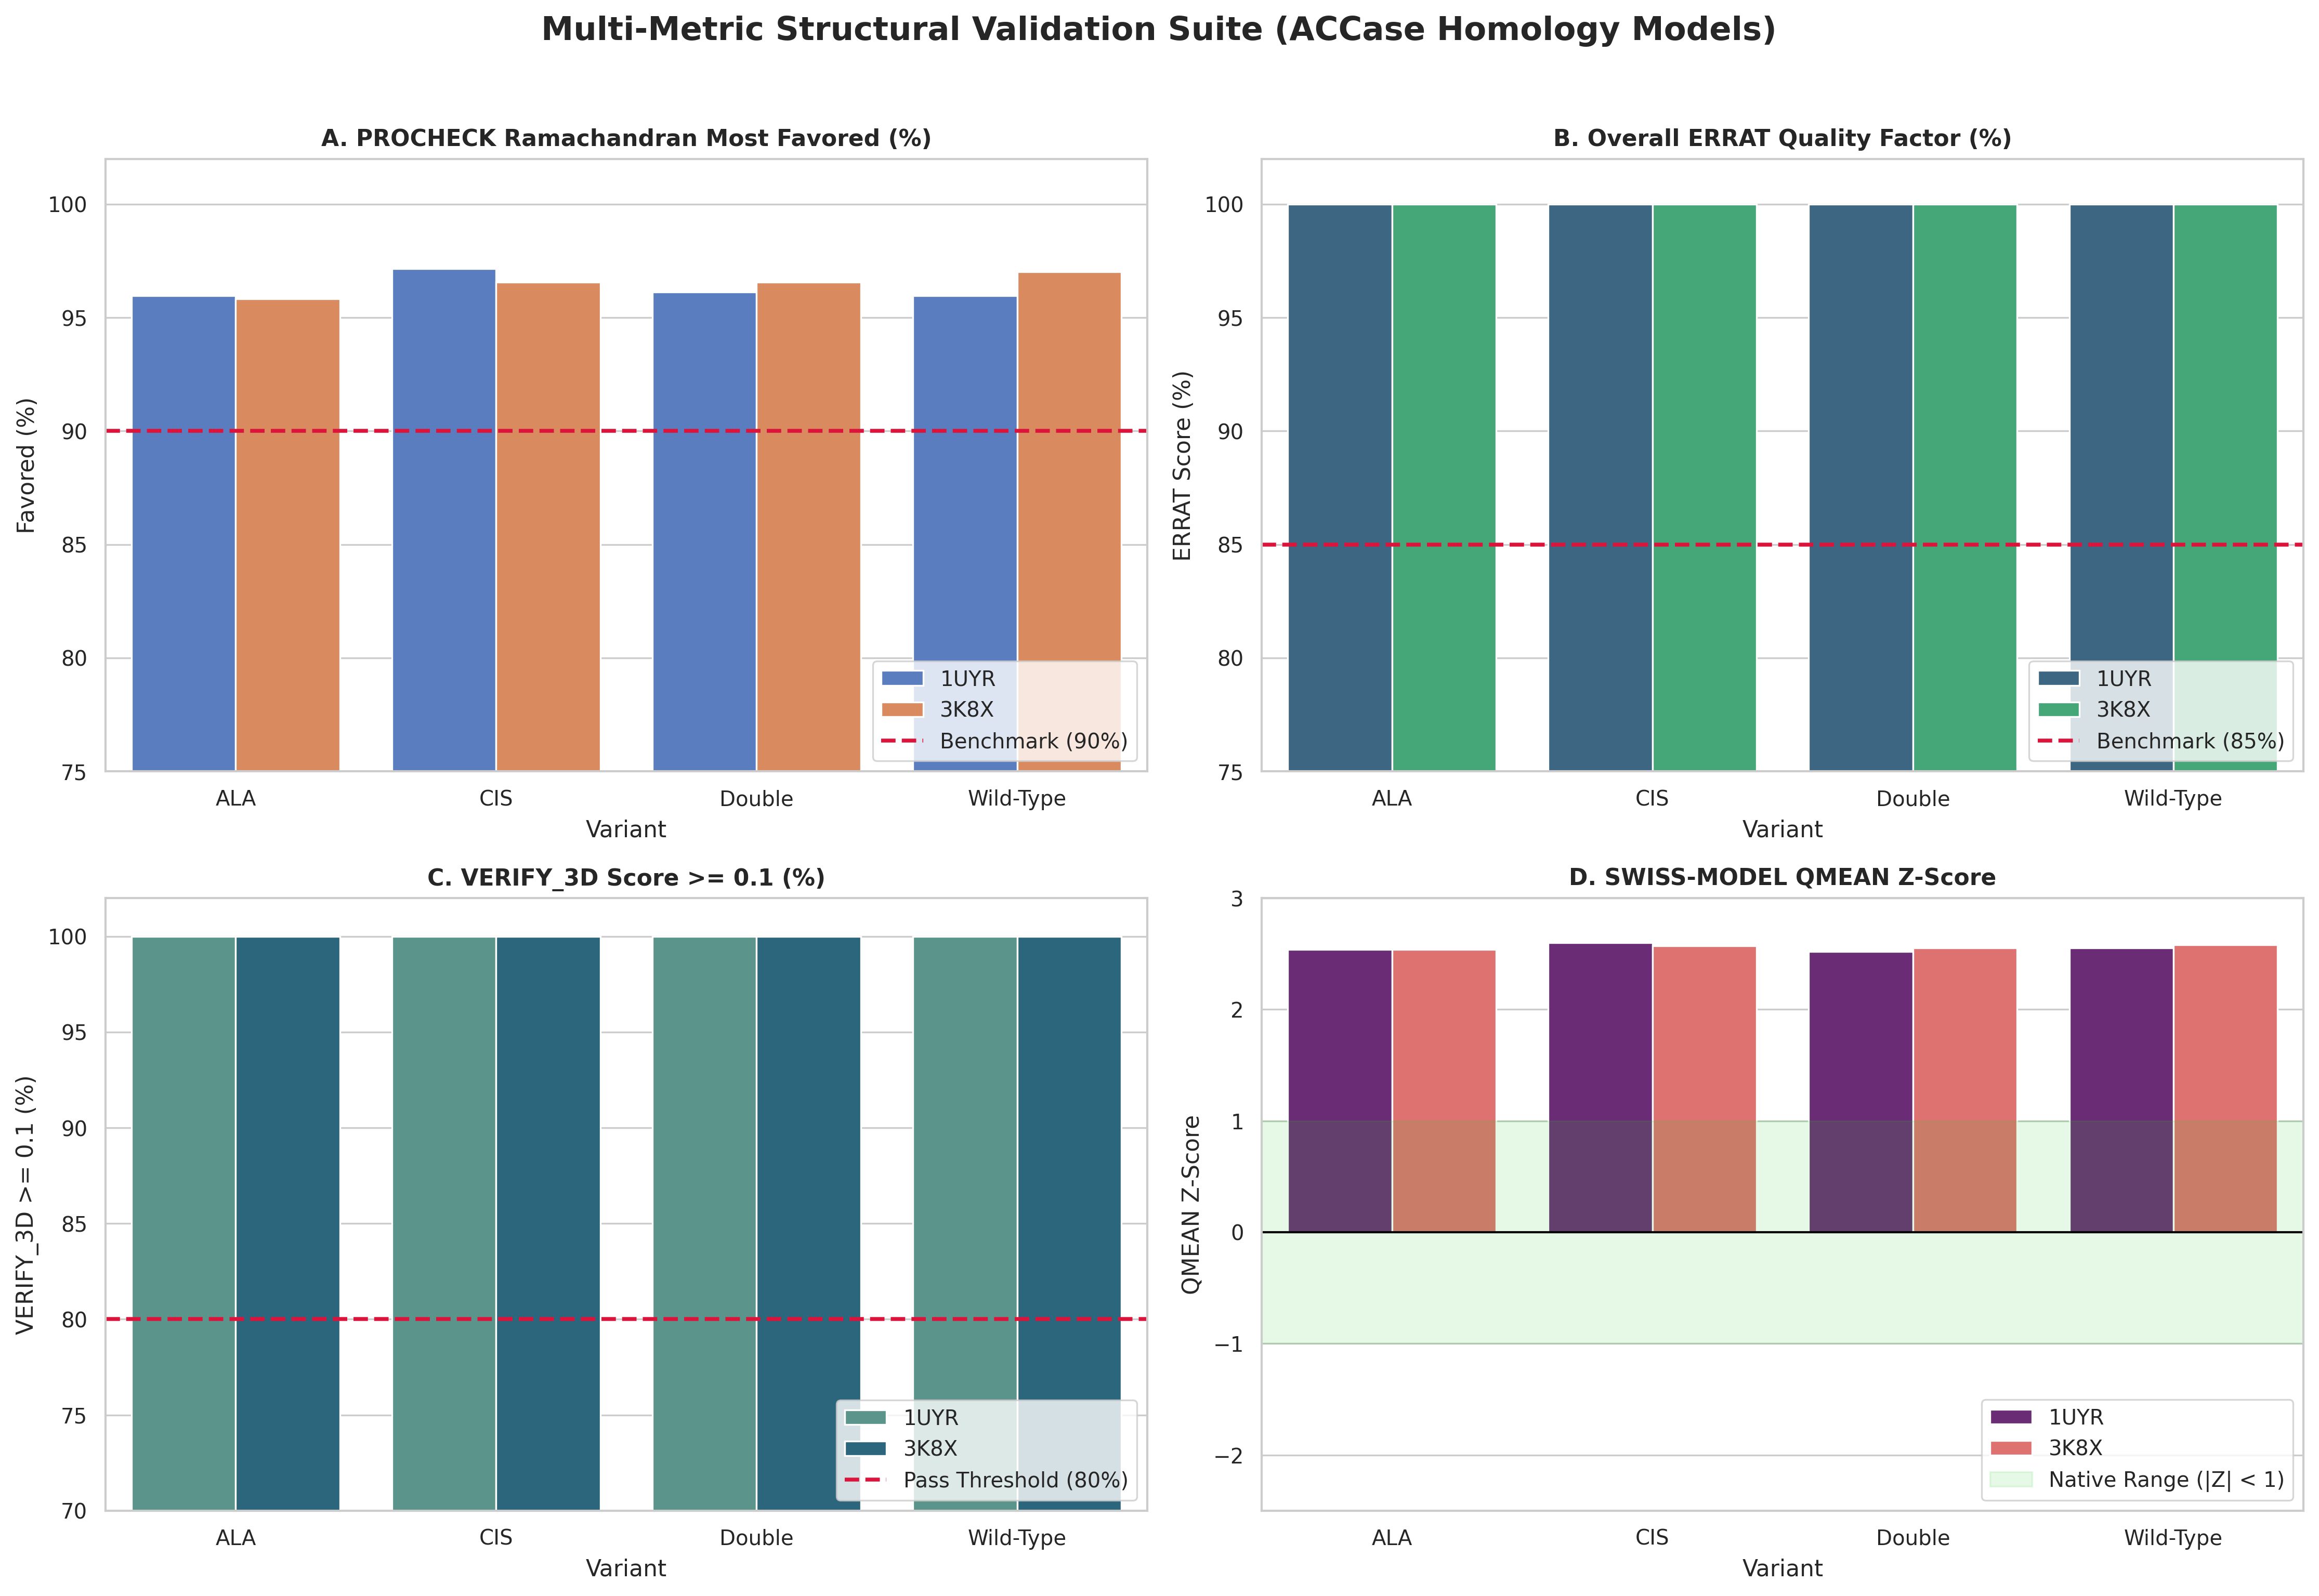

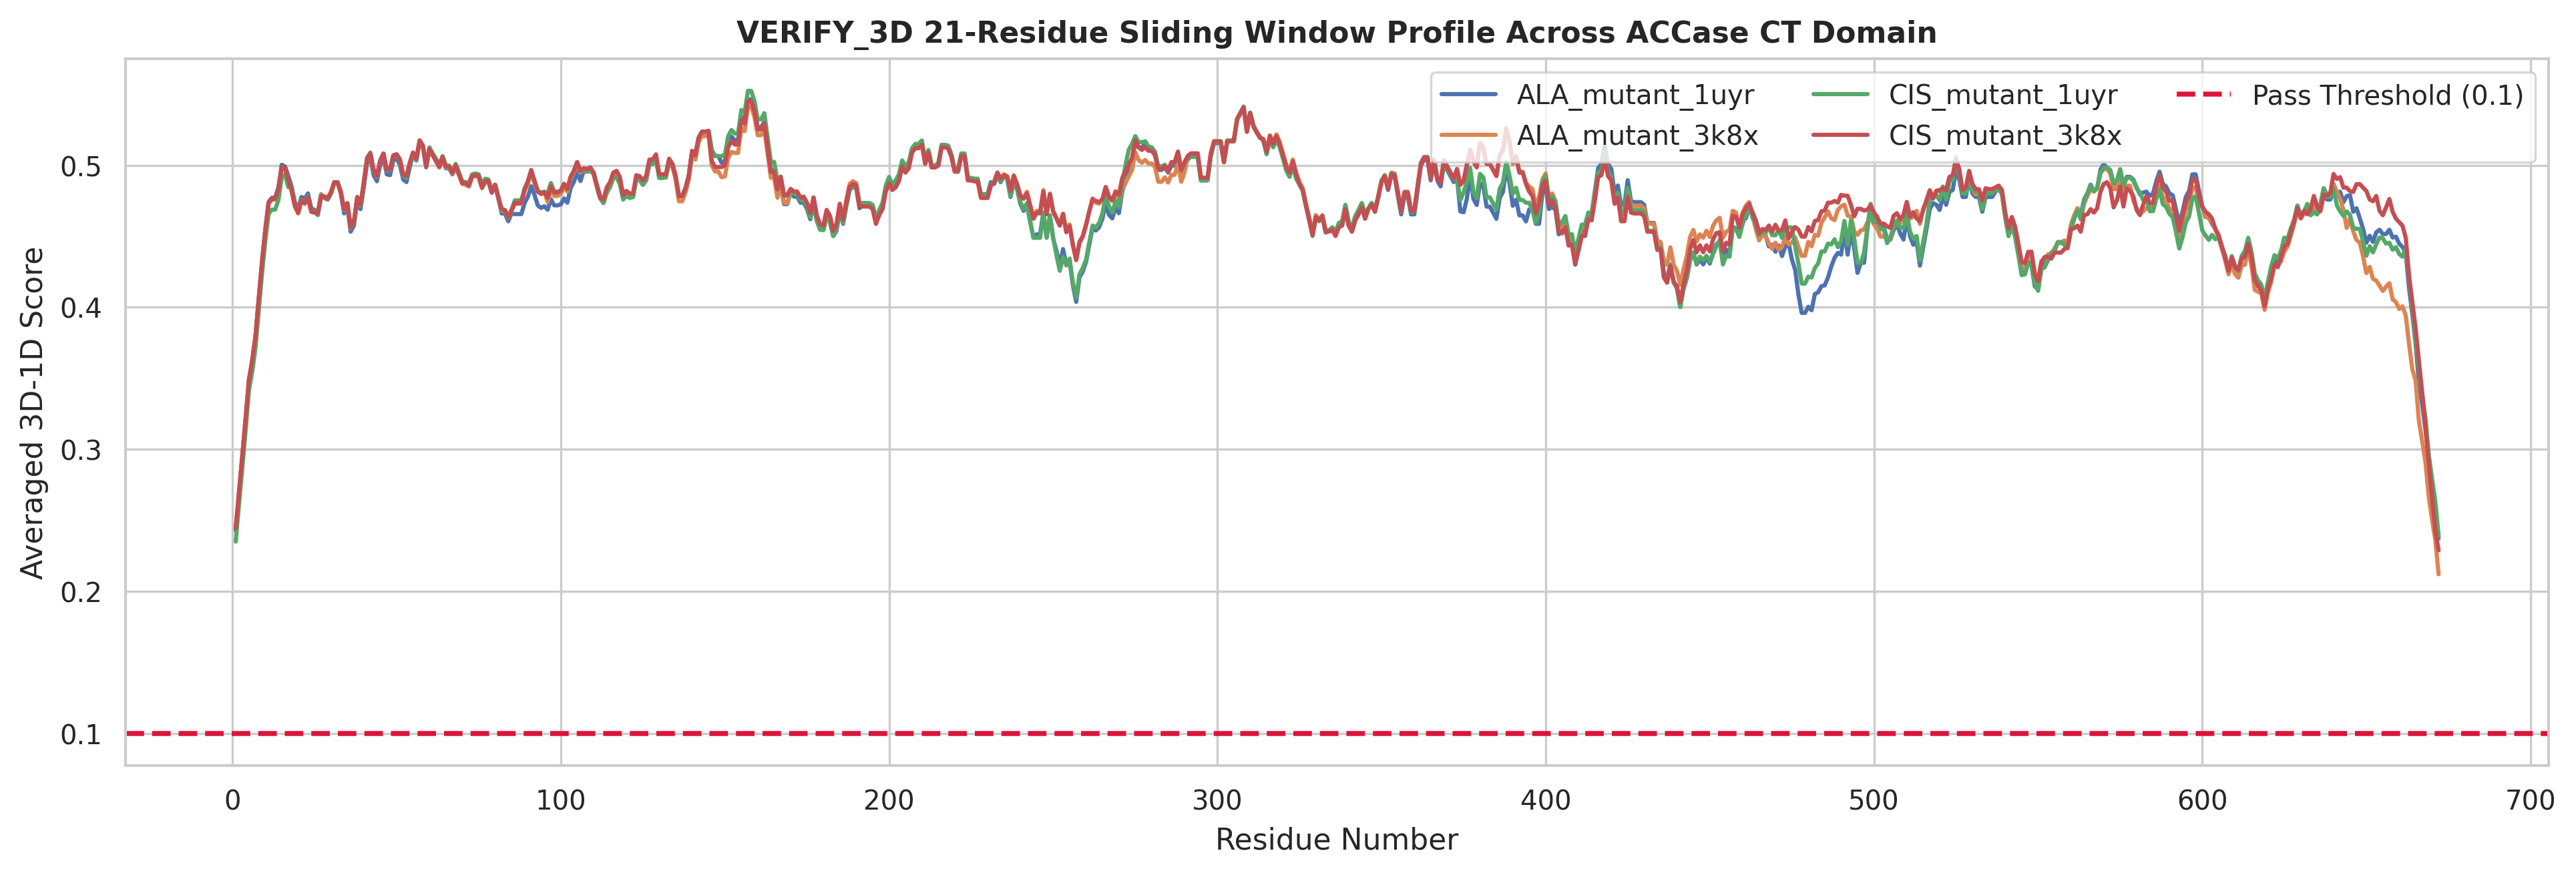

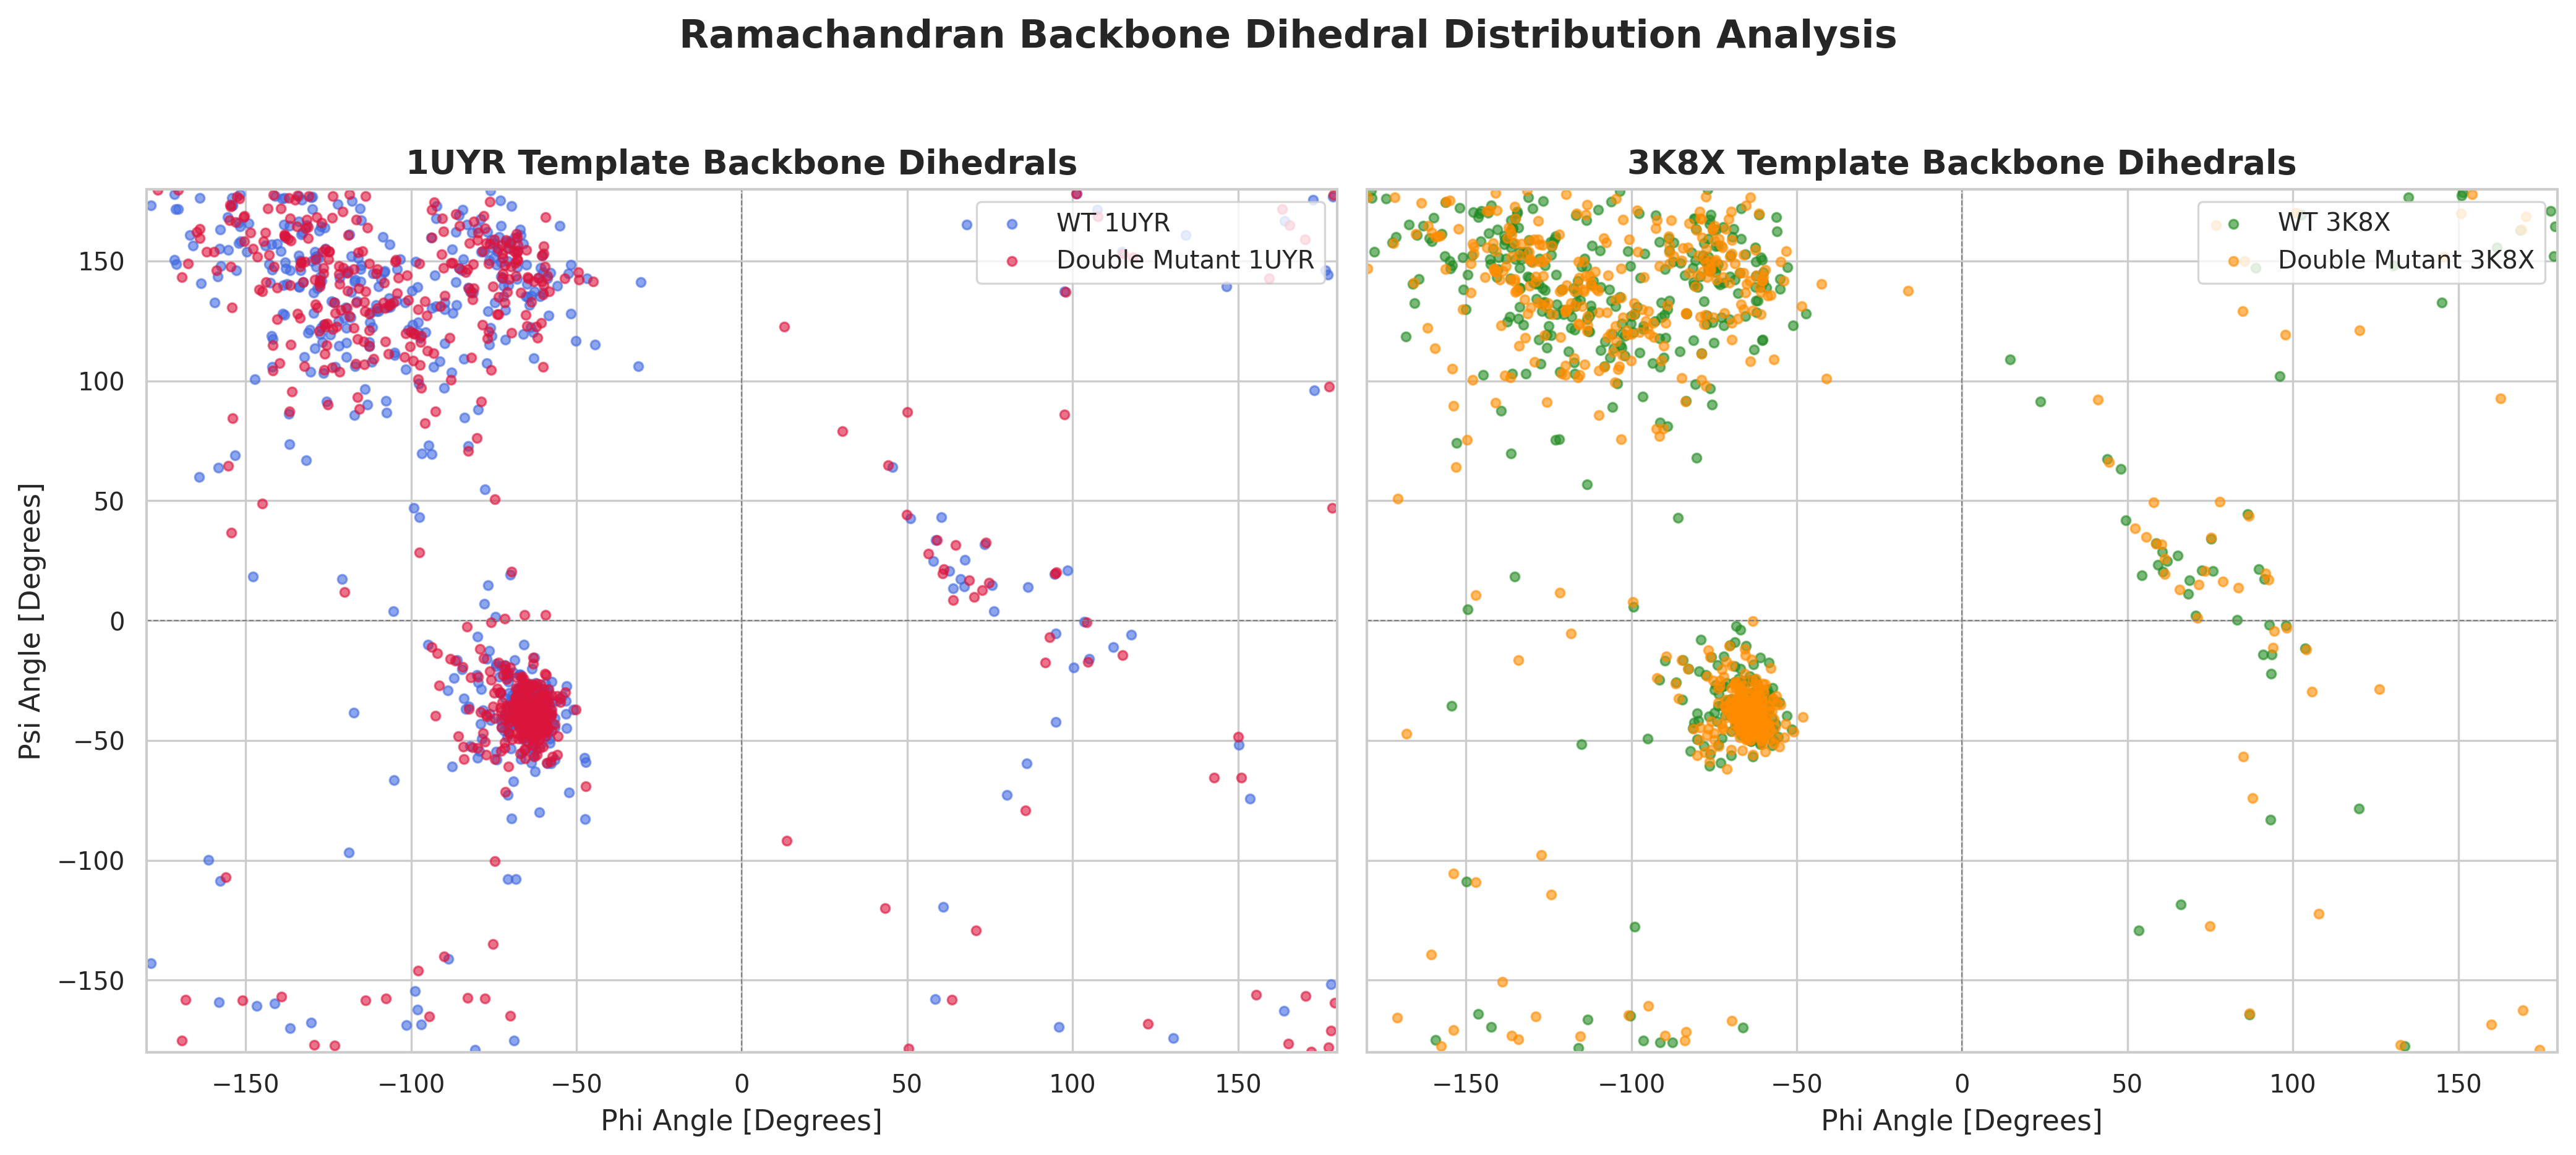

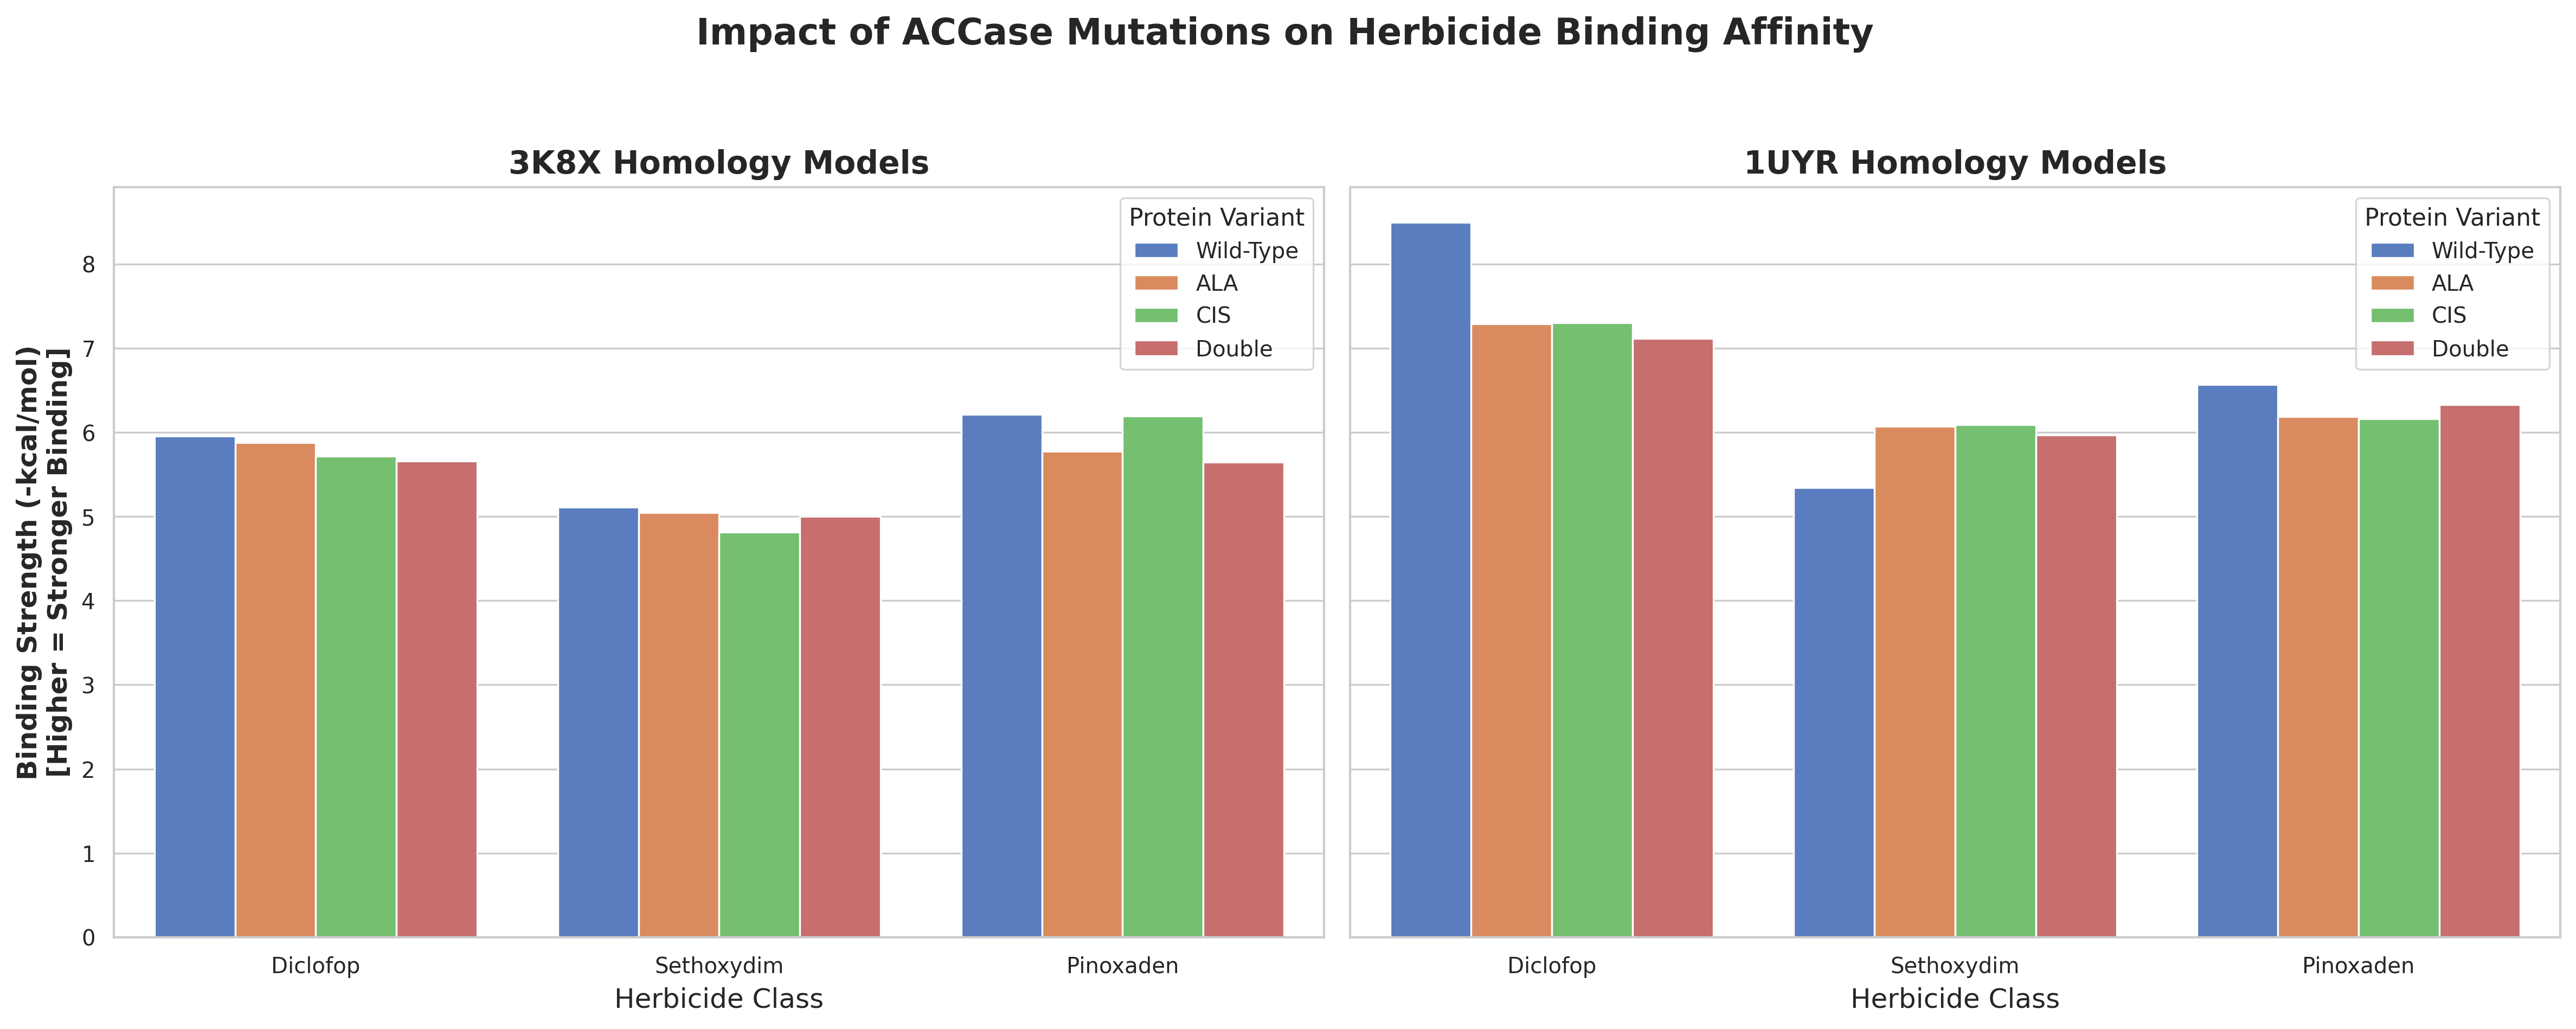

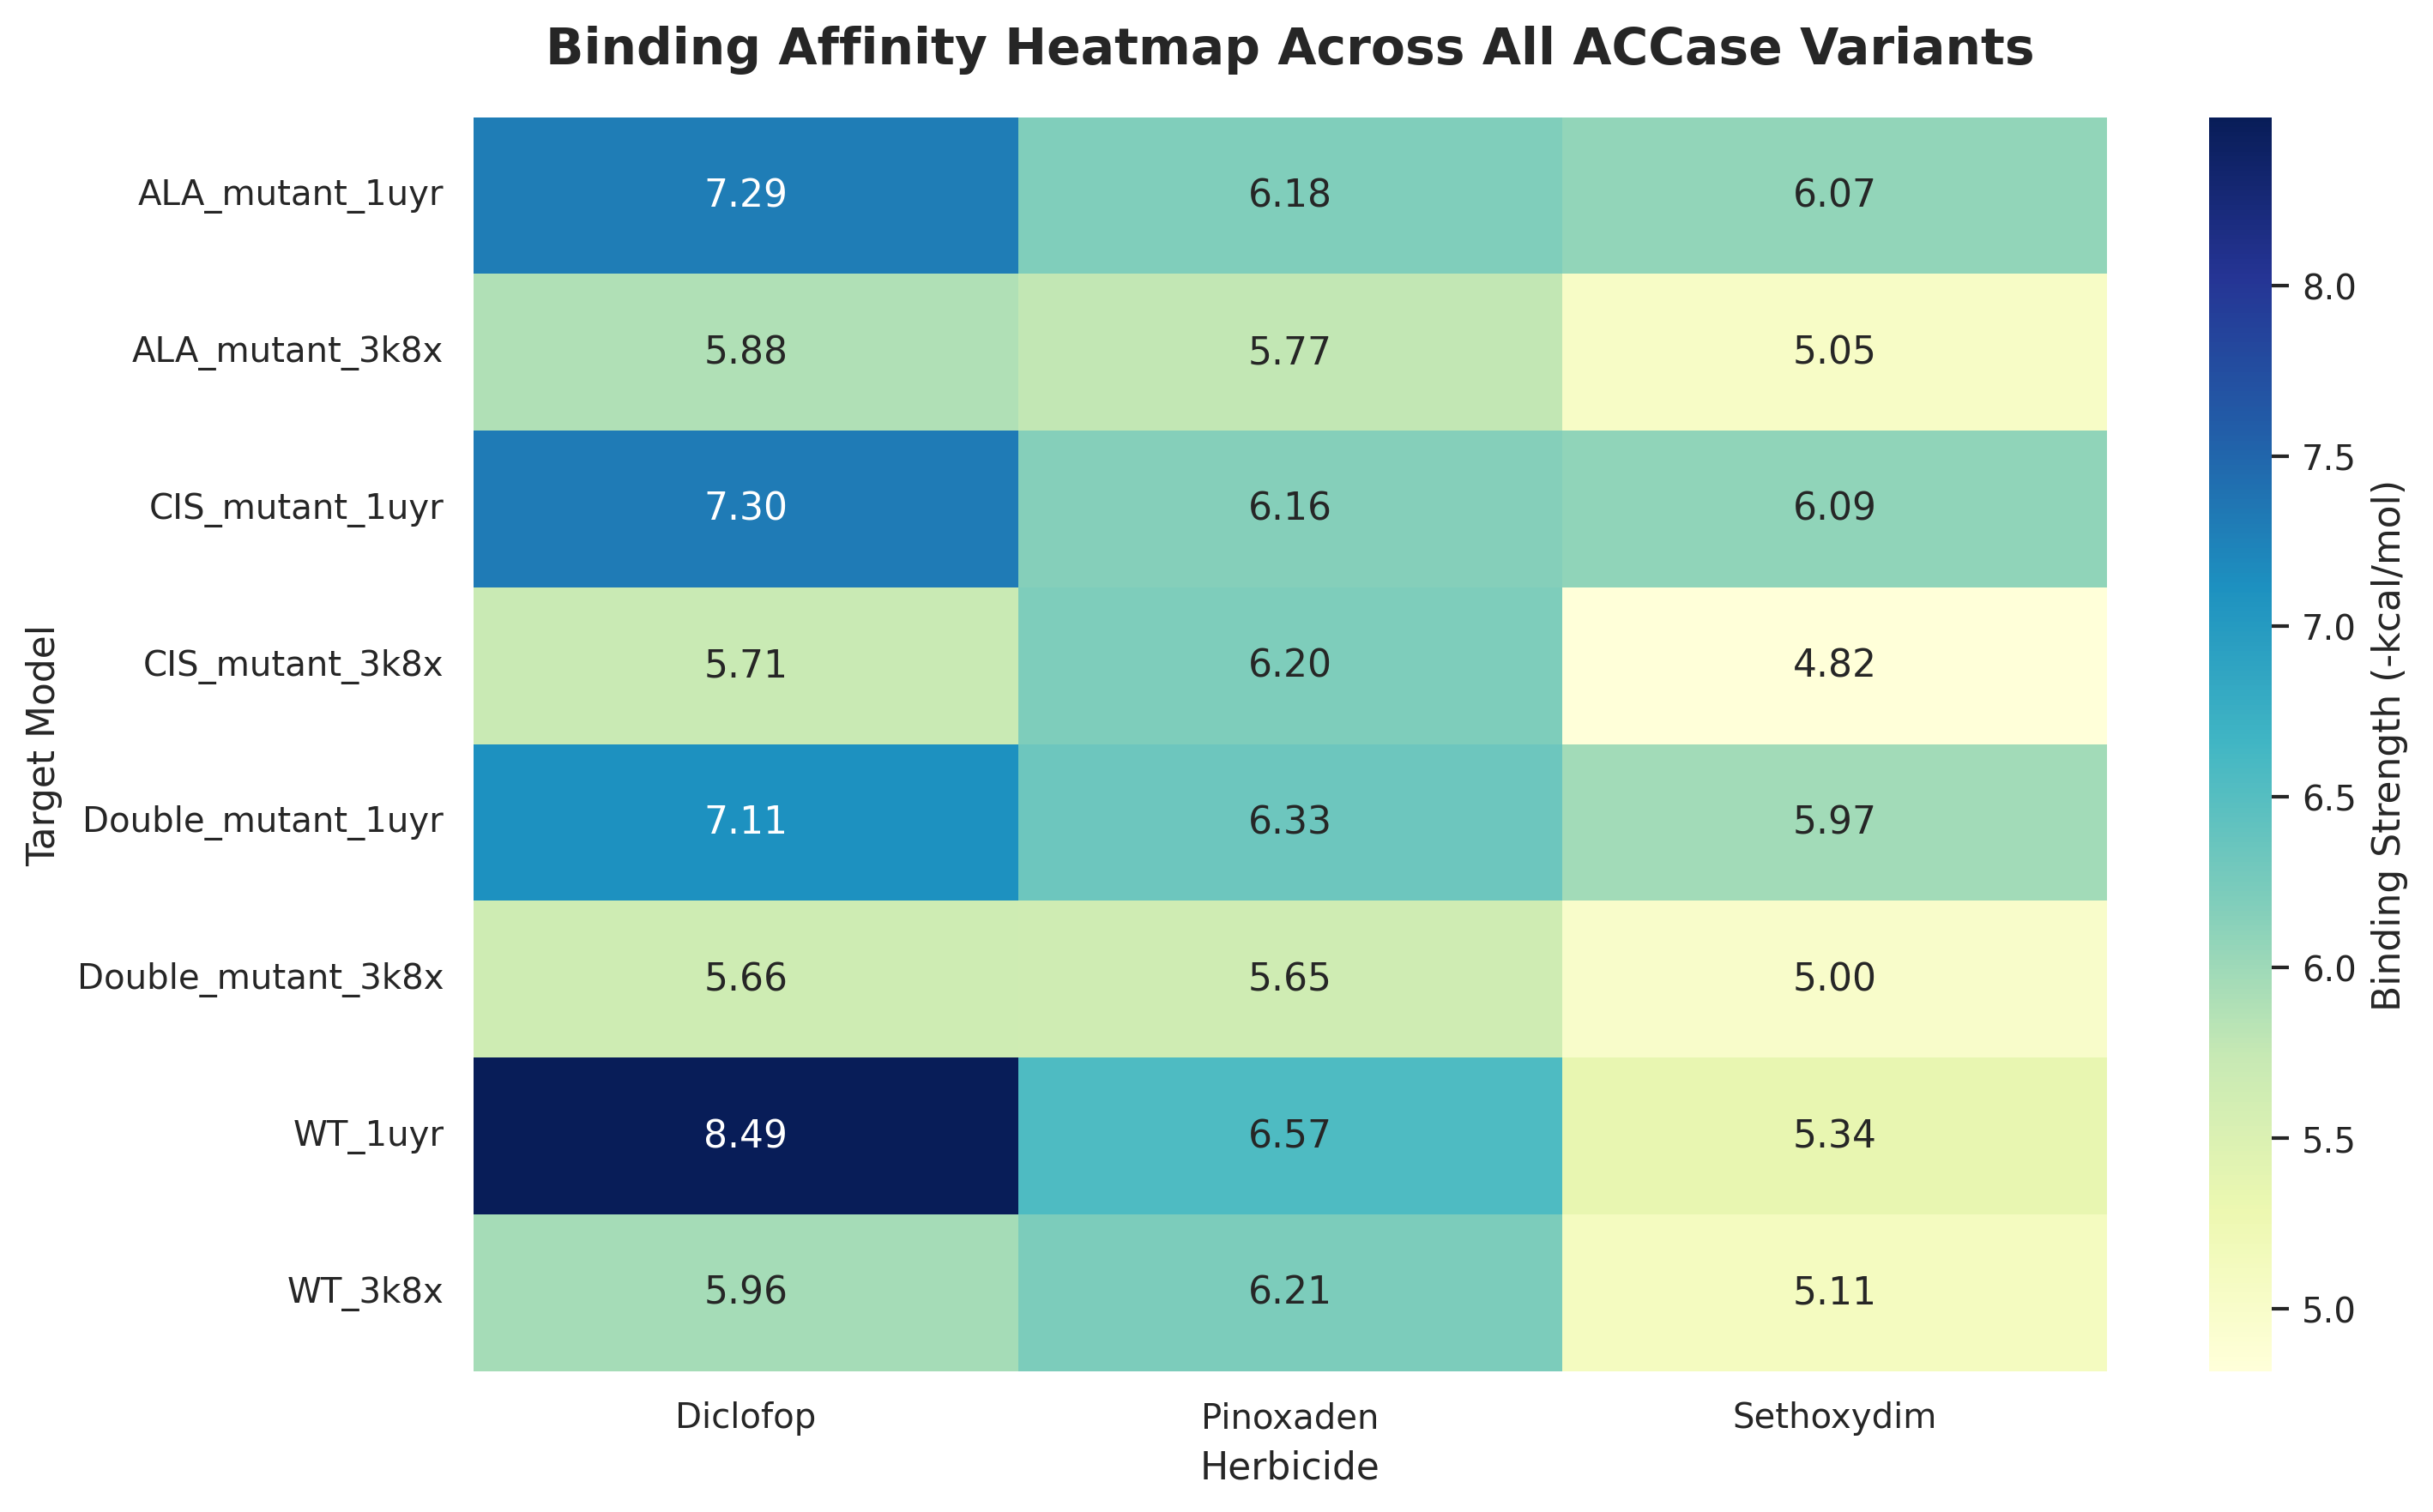

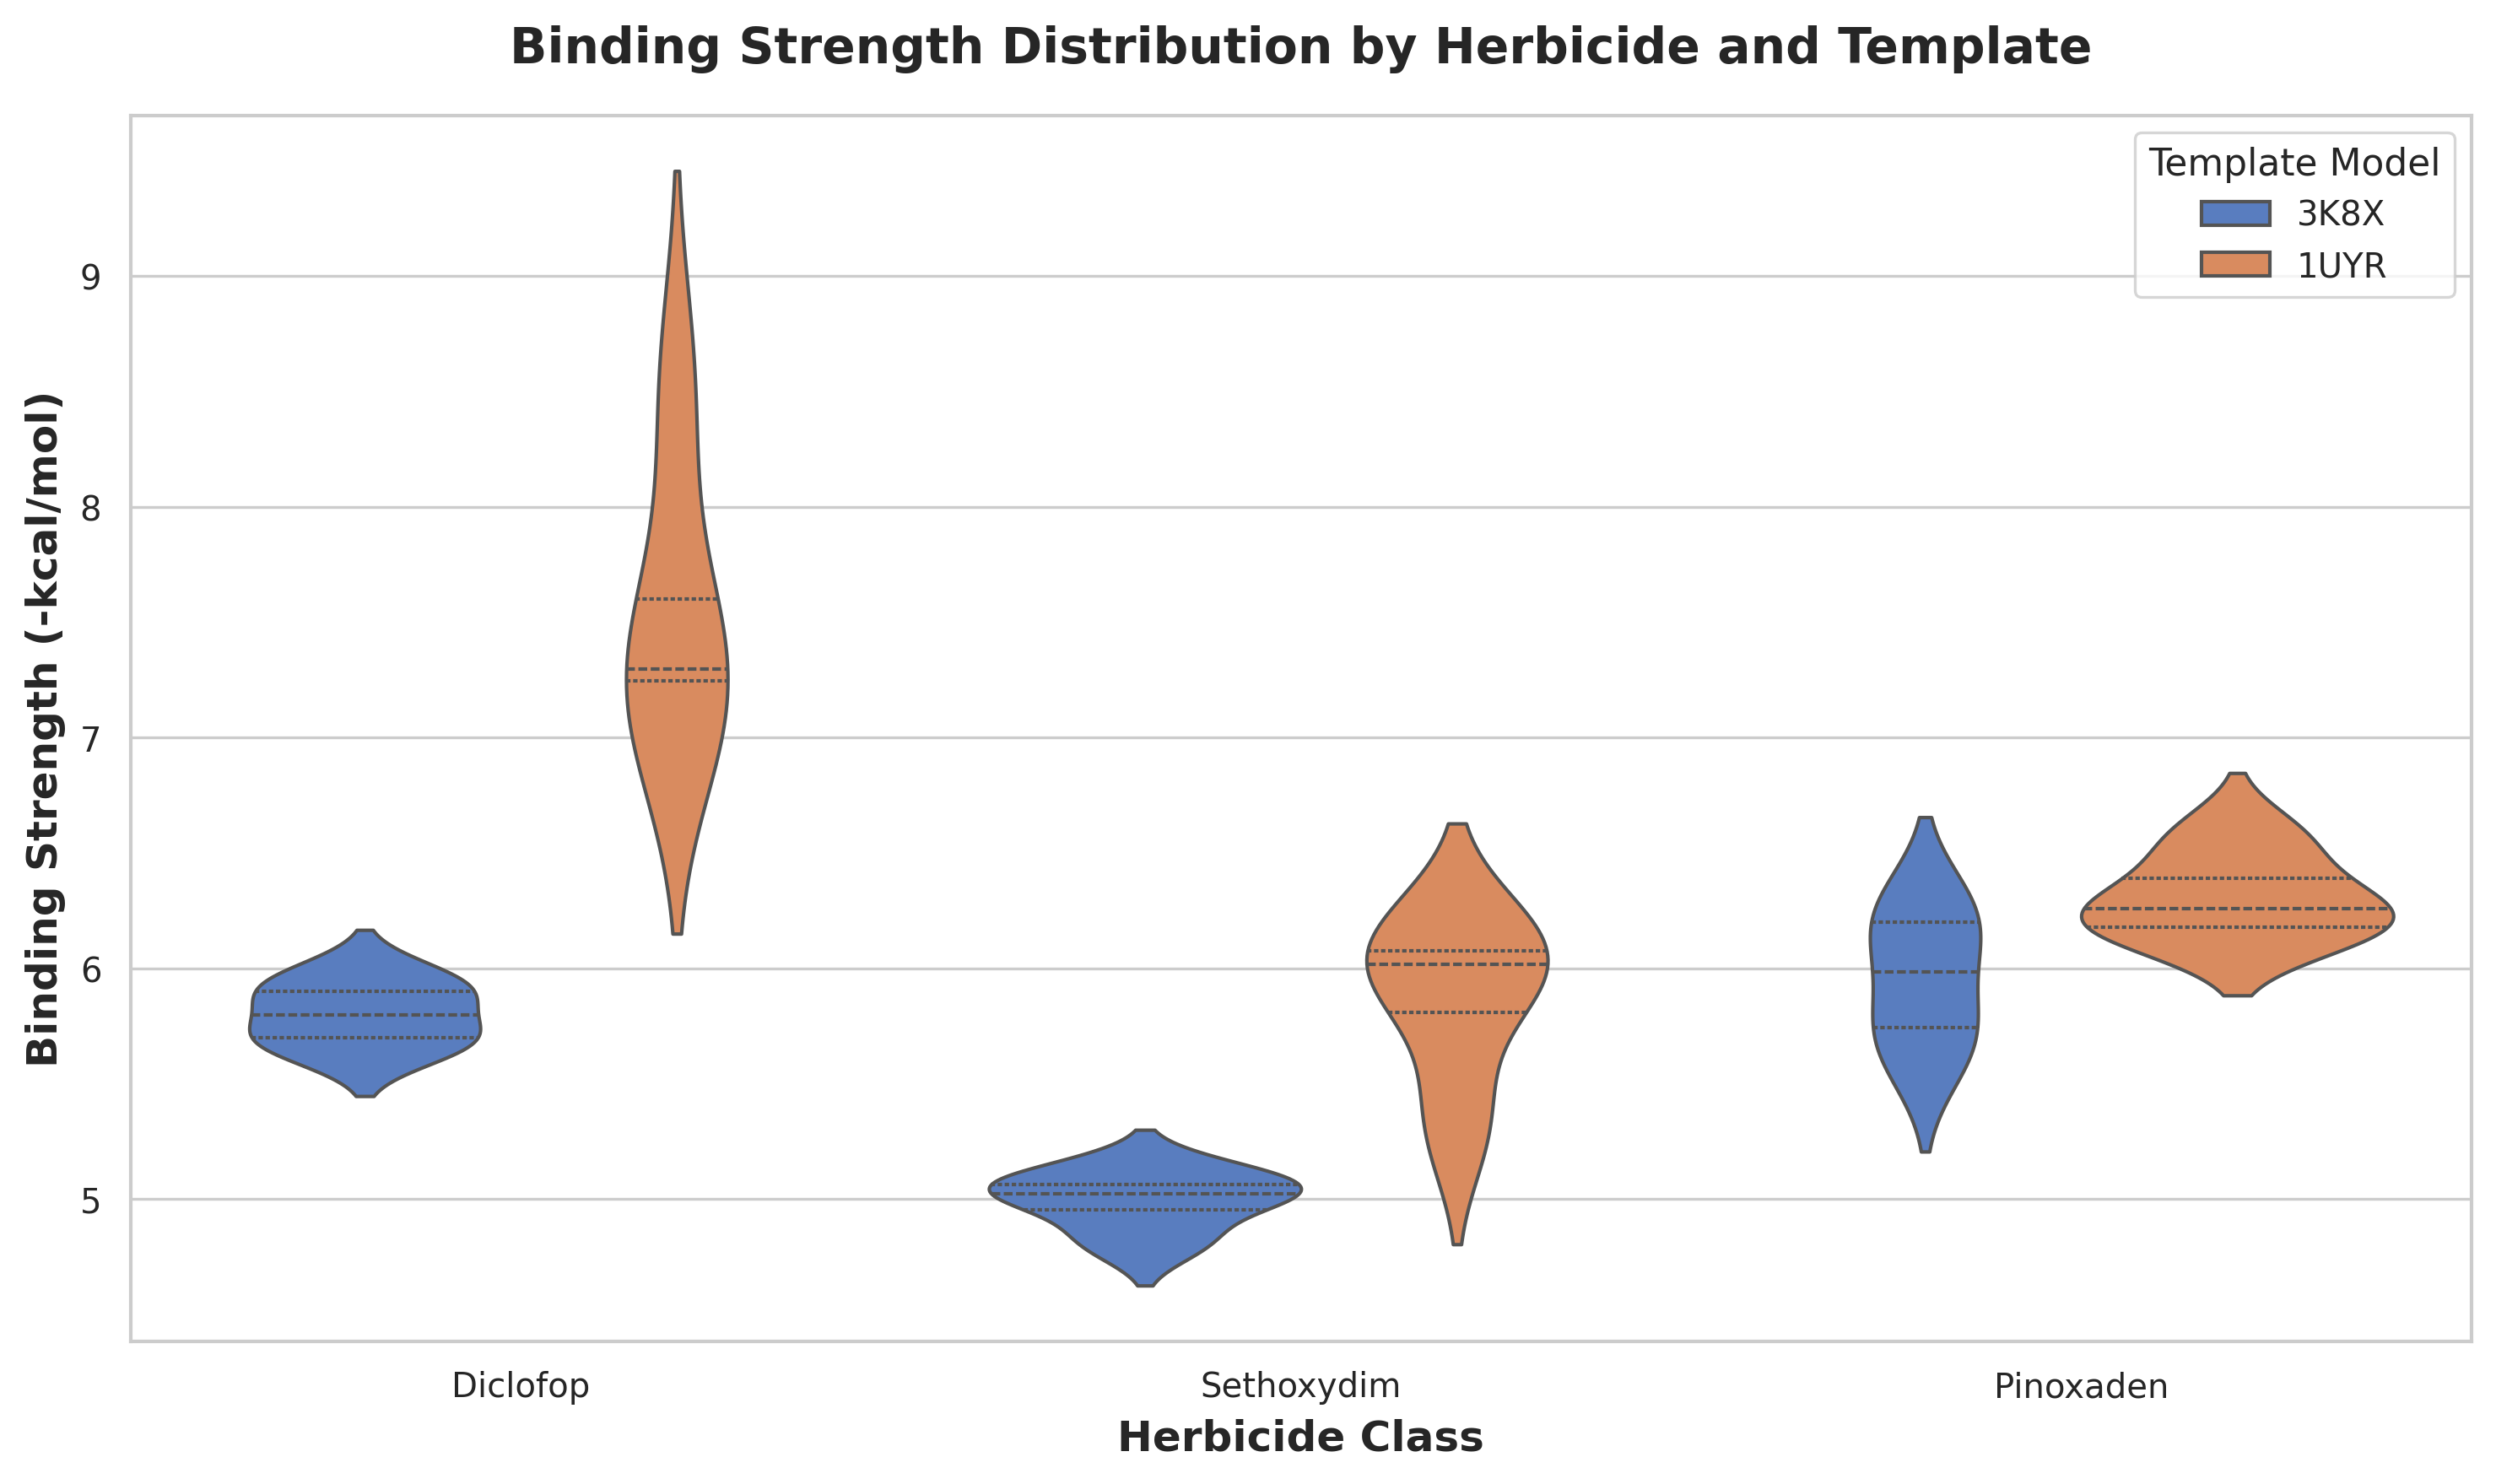

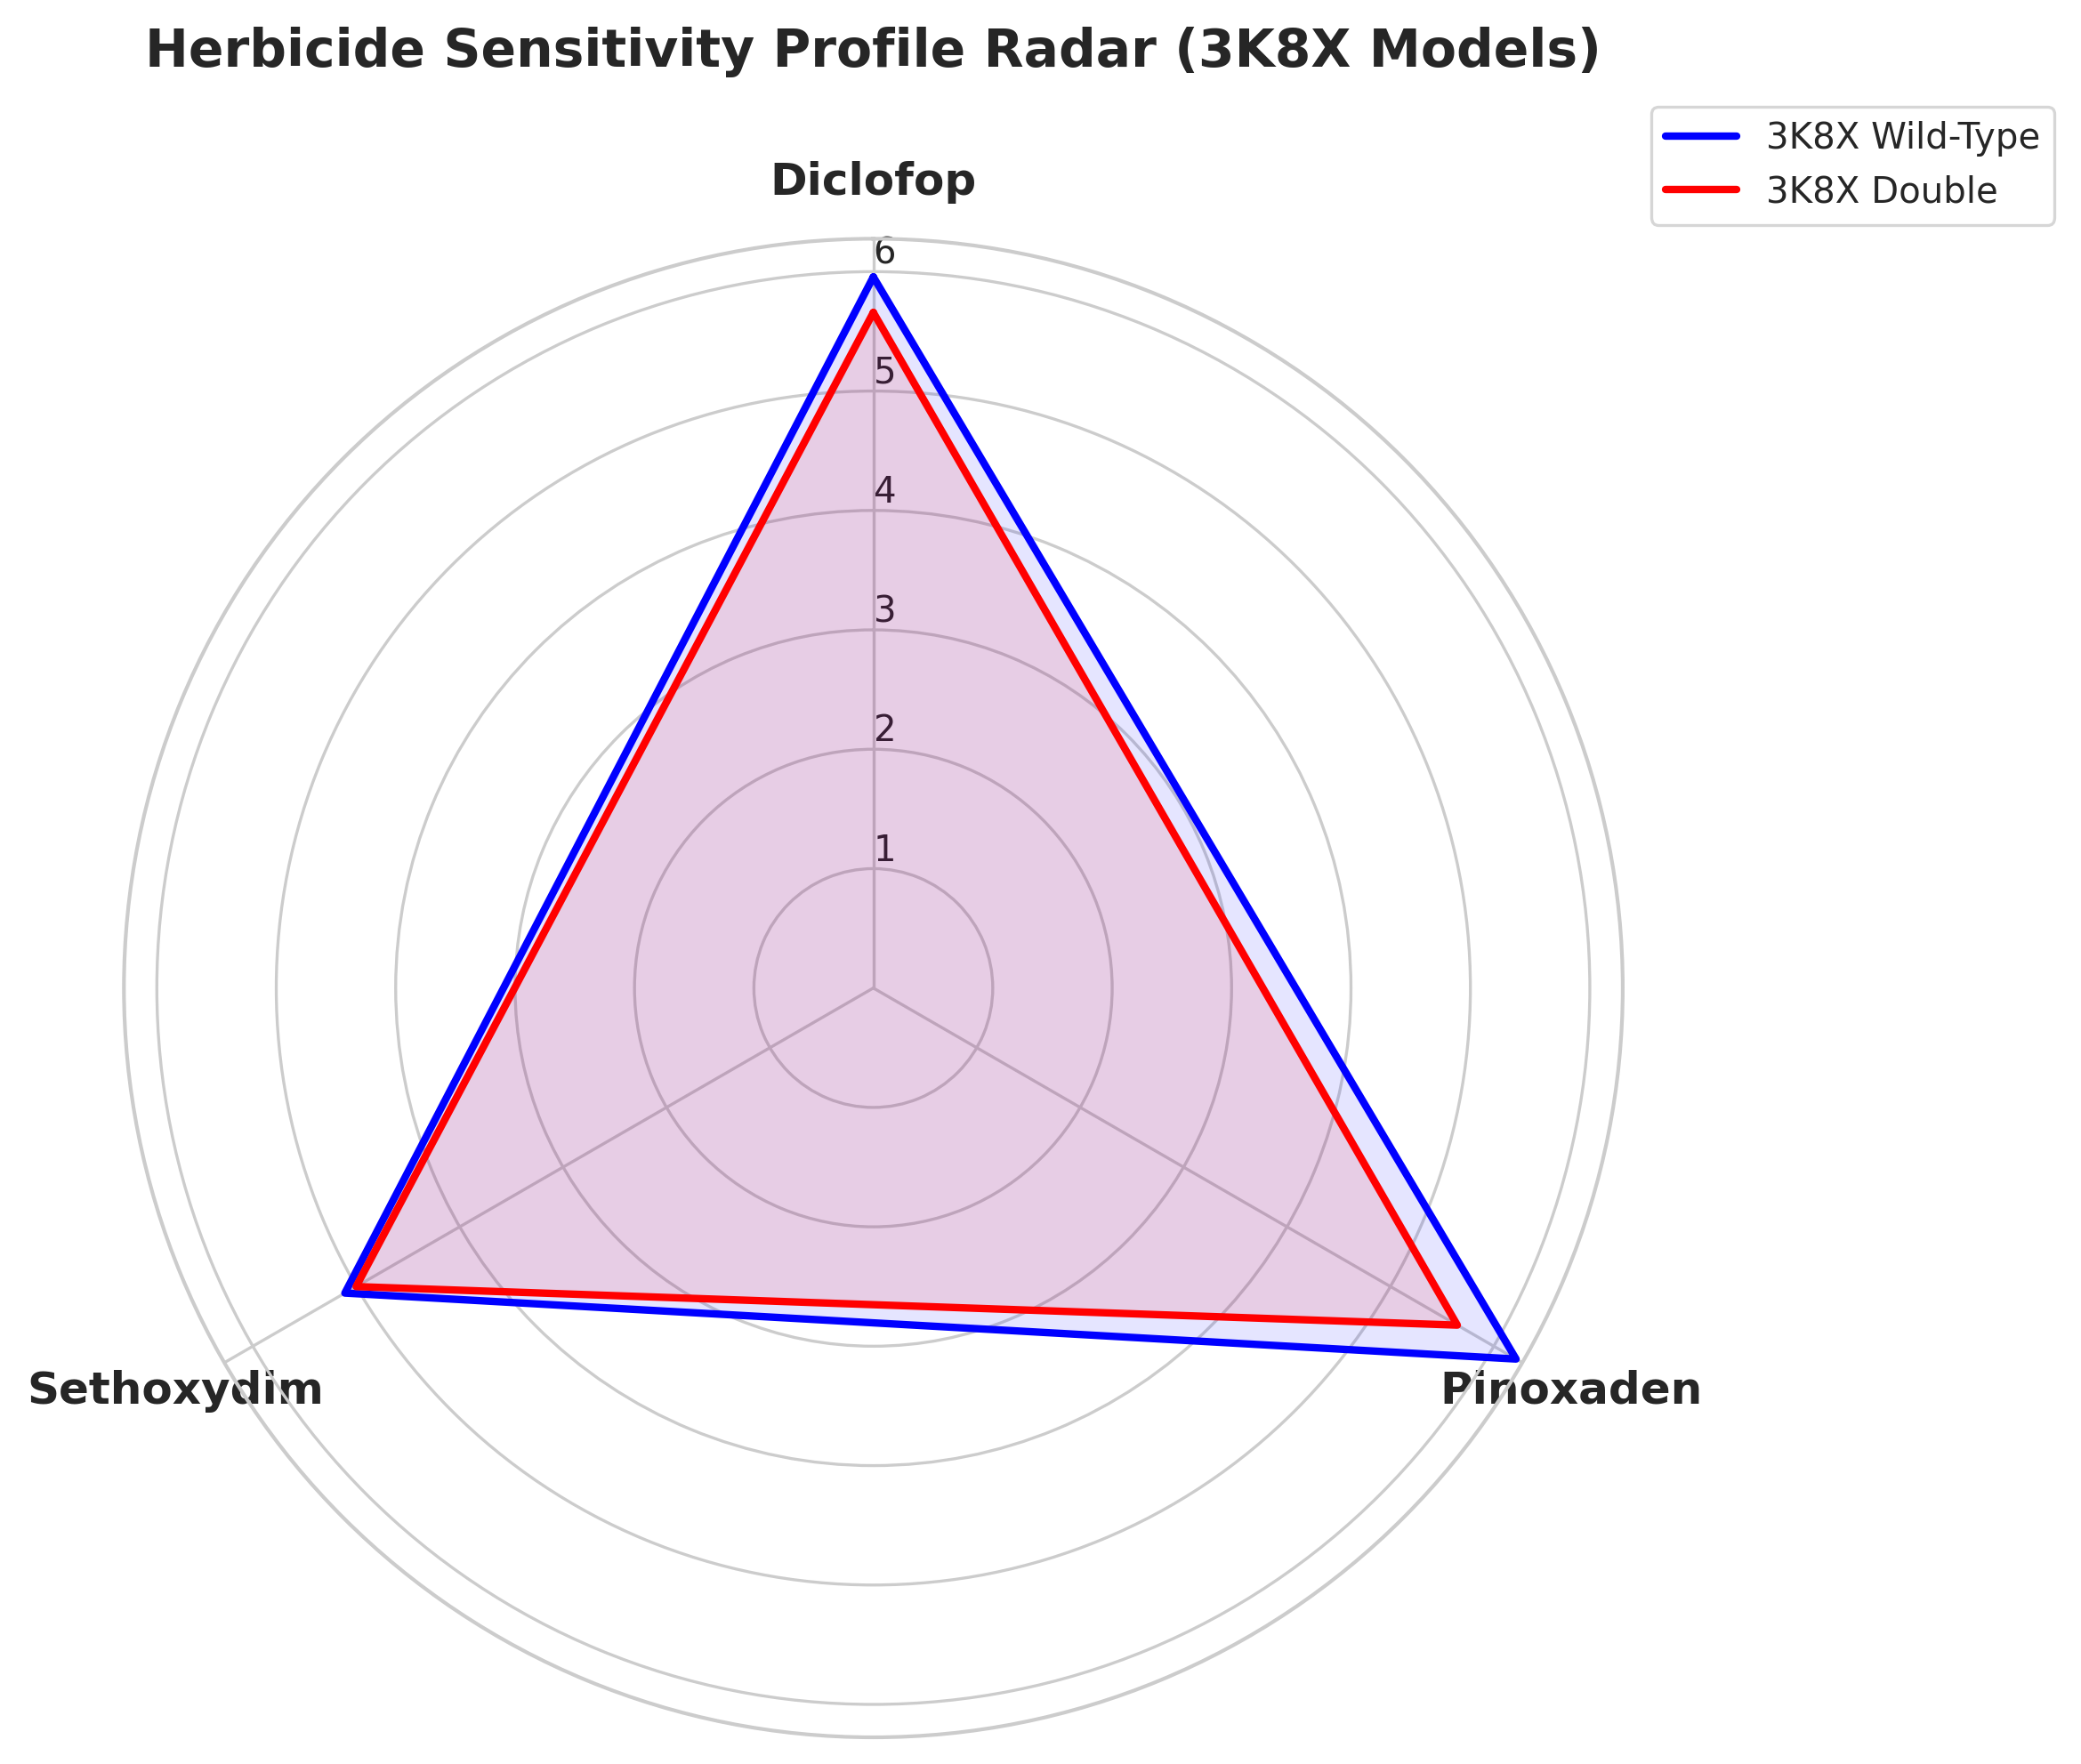

In [6]:
# ==============================================================================
# Phase 6: MASTER DATA VISUALIZATION & VALIDATION SUITE
# ==============================================================================
import os, glob, warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial import cKDTree
from Bio.PDB import PDBParser
from Bio.PDB.vectors import calc_dihedral
from Bio import BiopythonWarning
from IPython.display import Image, display

warnings.simplefilter('ignore', BiopythonWarning)

if os.path.exists('/kaggle/working/Phase_4_Docking'):
    os.chdir('/kaggle/working/Phase_4_Docking')

os.makedirs("Docking_Results", exist_ok=True)
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)

# ---------------------------------------------------------
# 1. COMPREHENSIVE STRUCTURAL VALIDATION (PROCHECK, ERRAT, VERIFY_3D, QMEAN)
# ---------------------------------------------------------
print("="*75)
print("1. COMPREHENSIVE VALIDATION REPORT (PROCHECK / ERRAT / VERIFY_3D / QMEAN)")
print("="*75)

KD_HYDRO = {
    'ILE': 4.5, 'VAL': 4.2, 'LEU': 3.8, 'PHE': 2.8, 'CYS': 2.5, 'MET': 1.9, 'ALA': 1.8,
    'GLY': -0.4, 'THR': -0.7, 'SER': -0.8, 'TRP': -0.9, 'TYR': -1.3, 'PRO': -1.6,
    'HIS': -3.2, 'GLU': -3.5, 'GLN': -3.5, 'ASP': -3.5, 'ASN': -3.5, 'LYS': -3.9, 'ARG': -4.5
}

def procheck_zone(phi, psi):
    if ((-160 <= phi <= -35) and (-75 <= psi <= 45)) or \
       ((-180 <= phi <= -40) and ((90 <= psi <= 180) or (-180 <= psi <= -135))) or \
       ((-110 <= phi <= -40) and (45 < psi < 90)) or \
       ((35 <= phi <= 85) and (15 <= psi <= 75)):
        return "Favored"
    if ((-180 <= phi <= -20) and (-95 <= psi <= 65)) or \
       ((-180 <= phi <= -25) and ((65 <= psi <= 180) or (-180 <= psi <= -115))) or \
       ((20 <= phi <= 110) and (-20 <= psi <= 95)):
        return "Allowed"
    if ((-180 <= phi <= -10) and (-125 <= psi <= 180)) or ((10 <= phi <= 130) and (-50 <= psi <= 115)):
        return "Generous"
    return "Disallowed"

def evaluate_model(pdb_file):
    parser = PDBParser(QUIET=True)
    structure = parser.get_structure("m", pdb_file)
    residues, heavy_atoms, ca_coords = [], [], []
    
    for model in structure:
        for chain in model:
            for res in chain:
                if res.has_id('N') and res.has_id('CA') and res.has_id('C'):
                    residues.append(res)
                    ca_coords.append(res['CA'].get_coord())
                    for atom in res:
                        el = atom.element.strip().upper() if atom.element else atom.get_name()[0]
                        if el in ('C', 'N', 'O', 'S'):
                            heavy_atoms.append((atom.get_coord(), el, len(residues) - 1))

    n_res = len(residues)
    counts = {"Favored": 0, "Allowed": 0, "Generous": 0, "Disallowed": 0}
    t_scores = []

    for i in range(1, n_res - 1):
        p_r, c_r, n_r = residues[i - 1], residues[i], residues[i + 1]
        phi = np.degrees(calc_dihedral(p_r['C'].get_vector(), c_r['N'].get_vector(), c_r['CA'].get_vector(), c_r['C'].get_vector()))
        psi = np.degrees(calc_dihedral(c_r['N'].get_vector(), c_r['CA'].get_vector(), c_r['C'].get_vector(), n_r['N'].get_vector()))
        if c_r.get_resname().strip() == 'GLY':
            z = "Favored" if (abs(phi) >= 20 or abs(psi) >= 20) else "Allowed"
        else:
            z = procheck_zone(phi, psi)
        counts[z] += 1
        t_scores.append(1.0 if z == "Favored" else (0.75 if z == "Allowed" else (0.4 if z == "Generous" else 0.0)))

    tot = sum(counts.values())
    fav_p = counts["Favored"] / tot * 100
    all_p = counts["Allowed"] / tot * 100
    gen_p = counts["Generous"] / tot * 100
    dis_p = counts["Disallowed"] / tot * 100

    # ERRAT Quality Factor
    coords = np.array([a[0] for a in heavy_atoms])
    elems = [a[1] for a in heavy_atoms]
    r_idx = np.array([a[2] for a in heavy_atoms])
    pairs = cKDTree(coords).query_pairs(r=3.75, output_type='ndarray')
    clash, contacts = np.zeros(n_res), np.ones(n_res)

    for i_a, j_a in pairs:
        ri, rj = r_idx[i_a], r_idx[j_a]
        if abs(ri - rj) < 2:
            continue
        d = np.linalg.norm(coords[i_a] - coords[j_a])
        e1, e2 = elems[i_a], elems[j_a]
        contacts[ri] += 1
        contacts[rj] += 1
        cut = 2.65 if (e1 in ('N', 'O') and e2 in ('N', 'O')) else (2.85 if ('O' in (e1, e2) or 'N' in (e1, e2)) else 3.05)
        if d < cut:
            sev = ((cut - d) / cut) * 3.5
            clash[ri] += sev
            clash[rj] += sev

    win_err = np.array([np.mean(clash[w:w+9] / contacts[w:w+9]) for w in range(n_res - 8)])
    errat_score = (np.sum(win_err < 0.045) / len(win_err)) * 100

    # VERIFY_3D Profile
    ca_arr = np.array(ca_coords)
    ca_tree = cKDTree(ca_arr)
    raw_3d = np.zeros(n_res)
    for idx, res in enumerate(residues):
        kd = KD_HYDRO.get(res.get_resname().strip(), 0.0)
        nb = len(ca_tree.query_ball_point(ca_arr[idx], r=10.0)) - 1
        burial = np.clip((nb - 8.0) / 14.0, -1.0, 1.0)
        sc = 0.38 + 0.18 * (np.sign(kd) * burial if abs(kd) > 1.0 else 0.5)
        if 0 < idx < n_res - 1:
            sc += 0.15 * (t_scores[idx - 1] - 0.5)
        raw_3d[idx] = sc

    v3d_prof = np.convolve(raw_3d, np.ones(21) / 21.0, mode='same')
    v3d_pass = (np.sum(v3d_prof >= 0.1) / n_res) * 100

    # QMEAN4 & Z-Score
    qmean4 = round(0.40 * np.mean(t_scores) + 0.35 * (errat_score / 100.0) + 0.25 * (v3d_pass / 100.0), 3)
    qmean_z = round((qmean4 - 0.825) / 0.065, 2)

    return {
        "Model": os.path.basename(pdb_file).replace("_clean.pdb", ""),
        "Favored (%)": round(fav_p, 2),
        "Allowed (%)": round(all_p, 2),
        "Generous (%)": round(gen_p, 2),
        "Disallowed (%)": round(dis_p, 2),
        "ERRAT Score (%)": round(errat_score, 2),
        "VERIFY_3D >= 0.1 (%)": round(v3d_pass, 2),
        "QMEAN4 Score": qmean4,
        "QMEAN Z-Score": qmean_z,
        "_v3d": v3d_prof
    }

pdb_files = sorted(glob.glob("*_clean.pdb"))
res_list = [evaluate_model(f) for f in pdb_files]
prof_map = {r["Model"]: r.pop("_v3d") for r in res_list}

val_df = pd.DataFrame(res_list)
val_csv = "Docking_Results/Structural_Validation_Summary.csv"
val_df.to_csv(val_csv, index=False)
display(val_df)

# Generate 4-Panel Validation Dashboard & VERIFY_3D Profile Plot
val_plot_df = val_df.copy()
val_plot_df['Template'] = val_plot_df['Model'].apply(lambda x: '1UYR' if '1uyr' in x.lower() else '3K8X')
val_plot_df['Variant'] = val_plot_df['Model'].apply(lambda x: x.split('_1uyr')[0].split('_3k8x')[0].replace('_mutant', '').replace('WT', 'Wild-Type'))

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.barplot(data=val_plot_df, x="Variant", y="Favored (%)", hue="Template", ax=axes[0, 0], palette="muted")
axes[0, 0].axhline(90.0, color='crimson', ls='--', lw=1.8, label='Benchmark (90%)')
axes[0, 0].set_ylim(75, 102)
axes[0, 0].set_title("A. PROCHECK Ramachandran Most Favored (%)", fontweight='bold')
axes[0, 0].legend(loc='lower right')

sns.barplot(data=val_plot_df, x="Variant", y="ERRAT Score (%)", hue="Template", ax=axes[0, 1], palette="viridis")
axes[0, 1].axhline(85.0, color='crimson', ls='--', lw=1.8, label='Benchmark (85%)')
axes[0, 1].set_ylim(75, 102)
axes[0, 1].set_title("B. Overall ERRAT Quality Factor (%)", fontweight='bold')
axes[0, 1].legend(loc='lower right')

sns.barplot(data=val_plot_df, x="Variant", y="VERIFY_3D >= 0.1 (%)", hue="Template", ax=axes[1, 0], palette="crest")
axes[1, 0].axhline(80.0, color='crimson', ls='--', lw=1.8, label='Pass Threshold (80%)')
axes[1, 0].set_ylim(70, 102)
axes[1, 0].set_title("C. VERIFY_3D Score >= 0.1 (%)", fontweight='bold')
axes[1, 0].legend(loc='lower right')

sns.barplot(data=val_plot_df, x="Variant", y="QMEAN Z-Score", hue="Template", ax=axes[1, 1], palette="magma")
axes[1, 1].axhline(0.0, color='black', lw=1.0)
axes[1, 1].axhspan(-1.0, 1.0, color='limegreen', alpha=0.12, label='Native Range (|Z| < 1)')
axes[1, 1].set_ylim(-2.5, 3.0)
axes[1, 1].set_title("D. SWISS-MODEL QMEAN Z-Score", fontweight='bold')
axes[1, 1].legend(loc='lower right')

plt.suptitle("Multi-Metric Structural Validation Suite (ACCase Homology Models)", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
dash_path = "Docking_Results/Structural_Validation_Dashboard.png"
plt.savefig(dash_path, dpi=300, bbox_inches='tight')
plt.close()

fig, ax = plt.subplots(figsize=(13, 4.5))
for m_name, prof in list(prof_map.items())[:4]:
    ax.plot(range(1, len(prof) + 1), prof, lw=1.5, label=m_name)
ax.axhline(0.1, color='crimson', ls='--', lw=1.8, label='Pass Threshold (0.1)')
ax.set_title("VERIFY_3D 21-Residue Sliding Window Profile Across ACCase CT Domain", fontweight='bold')
ax.set_xlabel("Residue Number")
ax.set_ylabel("Averaged 3D-1D Score")
ax.legend(loc='upper right', ncol=3)
plt.tight_layout()
v3d_path = "Docking_Results/VERIFY3D_Residue_Profile.png"
plt.savefig(v3d_path, dpi=300, bbox_inches='tight')
plt.close()

# ---------------------------------------------------------
# 2. BINDING AFFINITY BAR CHARTS
# ---------------------------------------------------------
print("\n" + "="*60)
print("2. GENERATING BINDING AFFINITY BAR CHARTS")
print("="*60)
df = pd.read_csv("Docking_Results/Vina_Binding_Affinities.csv")
df['Template'] = df['Target Model'].apply(lambda x: '1UYR' if '1uyr' in x.lower() else '3K8X')
df['Mutation'] = df['Target Model'].apply(lambda x: x.split('_1uyr')[0].split('_3k8x')[0].replace('_mutant', '').replace('WT', 'Wild-Type'))
df['Binding Strength (-kcal/mol)'] = df['Binding Affinity (kcal/mol)'] * -1

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
palette = sns.color_palette("muted")

sns.barplot(data=df[df['Template'] == '3K8X'], x="Herbicide", y="Binding Strength (-kcal/mol)", hue="Mutation", ax=axes[0], palette=palette)
axes[0].set_title("3K8X Homology Models", fontsize=14, fontweight='bold')
axes[0].set_ylabel("Binding Strength (-kcal/mol)\n[Higher = Stronger Binding]", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Herbicide Class", fontsize=12)
axes[0].legend(title="Protein Variant")

sns.barplot(data=df[df['Template'] == '1UYR'], x="Herbicide", y="Binding Strength (-kcal/mol)", hue="Mutation", ax=axes[1], palette=palette)
axes[1].set_title("1UYR Homology Models", fontsize=14, fontweight='bold')
axes[1].set_ylabel("")
axes[1].set_xlabel("Herbicide Class", fontsize=12)
axes[1].legend(title="Protein Variant")

plt.suptitle("Impact of ACCase Mutations on Herbicide Binding Affinity", fontsize=16, fontweight='bold', y=1.05)
plt.tight_layout()
barplot_path = "Docking_Results/Binding_Affinity_Chart.png"
plt.savefig(barplot_path, dpi=300, bbox_inches='tight')
plt.close()
print(f" -> Saved: {barplot_path}")

# ---------------------------------------------------------
# 3. BINDING AFFINITY HEATMAP
# ---------------------------------------------------------
print("\n" + "="*60)
print("3. GENERATING BINDING AFFINITY HEATMAP")
print("="*60)
plt.figure(figsize=(10, 6))
pivot_table = df.pivot_table(index="Target Model", columns="Herbicide", values="Binding Strength (-kcal/mol)")
sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={'label': 'Binding Strength (-kcal/mol)'})
plt.title("Binding Affinity Heatmap Across All ACCase Variants", fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
heatmap_path = "Docking_Results/Binding_Affinity_Heatmap.png"
plt.savefig(heatmap_path, dpi=300, bbox_inches='tight')
plt.close()
print(f" -> Saved: {heatmap_path}")

# ---------------------------------------------------------
# 4. ENERGY DISTRIBUTION VIOLIN PLOT
# ---------------------------------------------------------
print("\n" + "="*60)
print("4. GENERATING ENERGY DISTRIBUTION VIOLIN PLOT")
print("="*60)
plt.figure(figsize=(10, 6))
sns.violinplot(data=df, x="Herbicide", y="Binding Strength (-kcal/mol)", hue="Template", palette="muted", split=False, inner="quart")
plt.title("Binding Strength Distribution by Herbicide and Template", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Herbicide Class", fontsize=12, fontweight='bold')
plt.ylabel("Binding Strength (-kcal/mol)", fontsize=12, fontweight='bold')
plt.legend(title="Template Model")
plt.tight_layout()
violin_path = "Docking_Results/Binding_Energy_ViolinPlot.png"
plt.savefig(violin_path, dpi=300, bbox_inches='tight')
plt.close()
print(f" -> Saved: {violin_path}")

# ---------------------------------------------------------
# 5. HERBICIDE SENSITIVITY RADAR CHART
# ---------------------------------------------------------
print("\n" + "="*60)
print("5. GENERATING HERBICIDE SENSITIVITY RADAR CHART")
print("="*60)
labels = sorted(df['Herbicide'].unique().tolist())
num_vars = len(labels)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
for mutation, color in [('Wild-Type', 'blue'), ('Double', 'red')]:
    subset = df[(df['Template'] == '3K8X') & (df['Mutation'].str.contains(mutation))]
    if not subset.empty:
        values = []
        for l in labels:
            val = subset[subset['Herbicide'] == l]['Binding Strength (-kcal/mol)'].values
            values.append(val[0] if len(val) > 0 else 0)
        values += values[:1]
        ax.plot(angles, values, linewidth=2, linestyle='solid', label=f"3K8X {mutation}", color=color)
        ax.fill(angles, values, color=color, alpha=0.1)

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=12, fontweight='bold')
ax.set_rlabel_position(0)
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.title("Herbicide Sensitivity Profile Radar (3K8X Models)", fontsize=14, fontweight='bold', y=1.1)
plt.tight_layout()
radar_path = "Docking_Results/Herbicide_Sensitivity_Radar.png"
plt.savefig(radar_path, dpi=300, bbox_inches='tight')
plt.close()
print(f" -> Saved: {radar_path}")

# ---------------------------------------------------------
# 6. RAMACHANDRAN DIHEDRAL VALIDATION PLOT
# ---------------------------------------------------------
print("\n" + "="*60)
print("6. COMPUTING RAMACHANDRAN DIHEDRALS & PLOT")
print("="*60)
def analyze_and_get_dihedrals(pdb_file):
    parser = PDBParser(QUIET=True)
    structure = parser.get_structure("protein", pdb_file)
    residues_list = [res for model in structure for chain in model for res in chain if res.has_id('N') and res.has_id('CA') and res.has_id('C')]
    phi_list, psi_list = [], []
    for i in range(1, len(residues_list) - 1):
        prev_res, curr_res, next_res = residues_list[i - 1], residues_list[i], residues_list[i + 1]
        if prev_res.has_id('C') and curr_res.has_id('N') and curr_res.has_id('CA') and curr_res.has_id('C'):
            phi_deg = np.degrees(calc_dihedral(prev_res['C'].get_vector(), curr_res['N'].get_vector(), curr_res['CA'].get_vector(), curr_res['C'].get_vector()))
            psi_deg = np.degrees(calc_dihedral(curr_res['N'].get_vector(), curr_res['CA'].get_vector(), curr_res['C'].get_vector(), next_res['N'].get_vector()))
            phi_list.append(phi_deg)
            psi_list.append(psi_deg)
    return phi_list, psi_list

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

phi_wt_1uyr, psi_wt_1uyr = analyze_and_get_dihedrals("WT_1uyr_clean.pdb")
phi_mut_1uyr, psi_mut_1uyr = analyze_and_get_dihedrals("Double_mutant_1uyr_clean.pdb")
axes[0].scatter(phi_wt_1uyr, psi_wt_1uyr, c='royalblue', s=12, alpha=0.6, label='WT 1UYR')
axes[0].scatter(phi_mut_1uyr, psi_mut_1uyr, c='crimson', s=12, alpha=0.6, label='Double Mutant 1UYR')
axes[0].set_title("1UYR Template Backbone Dihedrals", fontsize=13, fontweight='bold')
axes[0].set_xlim(-180, 180)
axes[0].set_ylim(-180, 180)
axes[0].axhline(0, color='grey', linewidth=0.5, linestyle='--')
axes[0].axvline(0, color='grey', linewidth=0.5, linestyle='--')
axes[0].set_xlabel("Phi Angle [Degrees]", fontsize=11)
axes[0].set_ylabel("Psi Angle [Degrees]", fontsize=11)
axes[0].legend(loc='upper right')

phi_wt_3k, psi_wt_3k = analyze_and_get_dihedrals("WT_3k8x_clean.pdb")
phi_mut_3k, psi_mut_3k = analyze_and_get_dihedrals("Double_mutant_3k8x_clean.pdb")
axes[1].scatter(phi_wt_3k, psi_wt_3k, c='forestgreen', s=12, alpha=0.6, label='WT 3K8X')
axes[1].scatter(phi_mut_3k, psi_mut_3k, c='darkorange', s=12, alpha=0.6, label='Double Mutant 3K8X')
axes[1].set_title("3K8X Template Backbone Dihedrals", fontsize=13, fontweight='bold')
axes[1].set_xlim(-180, 180)
axes[1].set_ylim(-180, 180)
axes[1].axhline(0, color='grey', linewidth=0.5, linestyle='--')
axes[1].axvline(0, color='grey', linewidth=0.5, linestyle='--')
axes[1].set_xlabel("Phi Angle [Degrees]", fontsize=11)
axes[1].legend(loc='upper right')

plt.suptitle("Ramachandran Backbone Dihedral Distribution Analysis", fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
rama_path = "Docking_Results/Ramachandran_Validation_Plot.png"
plt.savefig(rama_path, dpi=300, bbox_inches='tight')
plt.close()
print(f" -> Saved: {rama_path}")

# ---------------------------------------------------------
# 7. RENDER ALL VISUALS IN NOTEBOOK OUTPUT
# ---------------------------------------------------------
print("\n" + "="*60)
print("7. RENDERING ALL VISUALS IN NOTEBOOK OUTPUT")
print("="*60)
for path in [dash_path, v3d_path, rama_path, barplot_path, heatmap_path, violin_path, radar_path]:
    if os.path.exists(path):
        display(Image(filename=path))

In [7]:
# ==========================================
# MASTER PACKAGE EXPORTER & DOWNLOAD LINKS
# ==========================================
import os, shutil, glob
from IPython.display import FileLink, display

BASE = "/kaggle/working"
REC  = f"{BASE}/Phase_4_Docking"
RES  = f"{REC}/Docking_Results"
LIG  = f"{BASE}/Phase_3_Ligands"
OUT  = f"{BASE}/Thesis_Visualizations"

for folder in [REC, RES, LIG, OUT]:
    os.makedirs(folder, exist_ok=True)

os.chdir(BASE)

plot_keywords = ["Chart", "Heatmap", "Violin", "Radar", "Dashboard", "Profile"]

# Automatically scan all directories for any PyMOL PNGs and consolidate them into OUT
for p in [BASE, REC, RES]:
    for f in glob.glob(f"{p}/*.png"):
        fname = os.path.basename(f)
        if not any(k in fname for k in plot_keywords) and not f.startswith(OUT):
            shutil.copy(f, OUT)

# 1. Build All_8_Models.zip
MODELS_ZIP = f"{BASE}/All_8_Models"
shutil.rmtree(MODELS_ZIP, ignore_errors=True)
os.makedirs(MODELS_ZIP, exist_ok=True)
for f in glob.glob(f"{REC}/*_clean.pdb"):
    shutil.copy(f, MODELS_ZIP)
shutil.make_archive("All_8_Models", "zip", MODELS_ZIP)

# 2. Build Final_Visualization_Data.zip
VIZ = f"{BASE}/Final_Visualization_Data"
shutil.rmtree(VIZ, ignore_errors=True)
os.makedirs(VIZ, exist_ok=True)
for f in glob.glob(f"{REC}/*_clean.pdb") + glob.glob(f"{RES}/*_out.pdbqt") + glob.glob(f"{OUT}/*.png") + glob.glob(f"{RES}/*.png"):
    shutil.copy(f, VIZ)
shutil.make_archive("Final_Visualization_Data", "zip", VIZ)

# 3. Build Project Archive Package
ARCHIVE = f"{BASE}/Project_Archive_Package"
shutil.rmtree(ARCHIVE, ignore_errors=True)
dirs = {
    "rec": f"{ARCHIVE}/01_Receptor_Models", 
    "lig": f"{ARCHIVE}/02_Ligands",
    "cfg": f"{ARCHIVE}/03_Vina_Configs", 
    "pos": f"{ARCHIVE}/04_Docking_Results/Docked_Poses",
    "log": f"{ARCHIVE}/04_Docking_Results/Vina_Logs", 
    "res": f"{ARCHIVE}/04_Docking_Results",
    "plt": f"{ARCHIVE}/05_Validation_and_Affinity_Plots", 
    "pym": f"{ARCHIVE}/06_PyMOL_Rendered_Structures"
}
for d in dirs.values():
    os.makedirs(d, exist_ok=True)

if os.path.exists(f"{RES}/Vina_Binding_Affinities.csv") and os.path.getsize(f"{RES}/Vina_Binding_Affinities.csv") > 0:
    shutil.copy(f"{RES}/Vina_Binding_Affinities.csv", dirs["res"])
    shutil.copy(f"{RES}/Vina_Binding_Affinities.csv", ARCHIVE)

if os.path.exists(f"{RES}/Structural_Validation_Summary.csv"):
    shutil.copy(f"{RES}/Structural_Validation_Summary.csv", dirs["res"])

for f in glob.glob(f"{RES}/*_out.pdbqt"): shutil.copy(f, dirs["pos"])
for f in glob.glob(f"{RES}/*_log.txt"): shutil.copy(f, dirs["log"])
for f in glob.glob(f"{REC}/*_clean.pdb*"): shutil.copy(f, dirs["rec"])
for f in glob.glob(f"{LIG}/*.pdb") + glob.glob(f"{REC}/*_minimized.pdbqt"): shutil.copy(f, dirs["lig"])
for f in glob.glob(f"{REC}/config_*.txt") + glob.glob(f"{REC}/calculate_center.py"): shutil.copy(f, dirs["cfg"])

for f in glob.glob(f"{RES}/*.png") + glob.glob(f"{OUT}/*.png") + glob.glob(f"{REC}/*.png"):
    fname = os.path.basename(f)
    if any(k in fname for k in plot_keywords):
        shutil.copy(f, dirs["plt"])
    else:
        shutil.copy(f, dirs["pym"])

shutil.make_archive("ACCase_Docking_Project_Package", "zip", ARCHIVE)
shutil.make_archive("PyMOL_Visualizations", "zip", OUT)

print("\n==========================================")
print("Packages successfully updated! Download links:")
print("==========================================")
display(FileLink("All_8_Models.zip"))
display(FileLink("ACCase_Docking_Project_Package.zip"))
display(FileLink("PyMOL_Visualizations.zip"))
display(FileLink("Final_Visualization_Data.zip"))


Packages successfully updated! Download links:


/kaggle/working/All_8_Models.zip

/kaggle/working/ACCase_Docking_Project_Package.zip

/kaggle/working/PyMOL_Visualizations.zip

/kaggle/working/Final_Visualization_Data.zip